# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 **질문 → 원본 데이터 점검 → 전처리 → PK/FK 검증 → 안전한 병합 → completed 범위 집계 → 총합 대조 → 시각화 → 보고서 → 최종 Validation**을 하나의 재현 가능한 프로젝트로 연결합니다.

> 코드가 끝까지 실행되었다는 사실만으로 프로젝트가 검증된 것은 아닙니다. 같은 의미의 숫자와 공개 산출물이 정해 둔 기준을 함께 통과해야 합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 PK의 결측·중복과 FK 미매칭을 확인합니다.
- `validate`와 `indicator` 관점으로 병합 결과를 검증합니다.
- `line_total = quantity × unit_price`를 다시 확인합니다.
- 금액성 분석은 `order_status == "completed"` 범위를 사용합니다.
- 카테고리·월·고객 금액 합계를 같은 source total과 대조합니다.
- 날짜 오류로 월별 금액이 누락되지 않는지 확인합니다.
- 공개 고객 결과에서 원본 고객 ID와 직접 식별정보를 제거합니다.
- 결과 CSV, 그래프, Markdown 보고서와 PASS/FAIL Evidence를 저장합니다.
- 전체 파이프라인을 다시 실행해 재현성을 확인합니다.


## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


### 분석 질문과 완료 기준

- 대상은 공식 쇼핑몰 실습 데이터이며 실제 기업 매출로 해석하지 않음
- 질문 1: 카테고리별 completed 주문 금액은 어떻게 다른가 → 주문·상세·상품 사용, 금액·수량·비중 계산, 카테고리 합계가 source total과 일치하면 완료
- 질문 2: 월별 completed 주문 금액과 주문 수는 어떻게 변하는가 → 주문·상세 사용, 월별 금액·고유 주문 수·평균 금액 계산, 날짜 오류 0건이며 월 합계가 source total과 일치하면 완료
- 질문 3: completed 구매 금액 상위 익명 고객의 구매 규모와 빈도는 어떠한가 → 고객·주문·상세 사용, 고객별 금액·고유 주문 수·평균 금액 계산, 고객 합계 일치 및 공개 식별정보 제거 시 완료
- 범위는 파일에 있는 전체 기간, 금액은 completed만 사용하고 주문 상세 수와 고유 주문 수를 구분함
- 원본은 커밋과 SHA-256으로 고정하며 이전 Chapter의 별도 전처리 데이터와 혼합하지 않음
- 실행 전 필요 패키지: pandas, numpy, matplotlib, IPython / 다운로드가 필요할 때 인터넷 연결 필요함


In [1]:
from pathlib import Path
import sys, tempfile, hashlib, shutil, urllib.request, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
PROJECT_ROOT = Path(tempfile.mkdtemp(prefix="ch08_"))
RAW_DIR = PROJECT_ROOT / "data/raw"
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"
for path in [RAW_DIR, PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)
COURSE_COMMIT = '6105f42bd8294cb364dde6dcc2fee71c32e14794'
RAW_HASHES = {'customers.csv': '3b31aaefa66505f0a1820ccd89f0eac3b5e12830b71ecb45f2b65928bcdfb143', 'products.csv': '46ff06753ade3e71011ee08dd366148dcd9c36521f111840cead0a9d1047e405', 'orders.csv': '8f6e7ee39aa5ee6e229199532caa84bd9d4d30ef2abc2b9412cf45b0b2fdbfae', 'order_items.csv': 'a7a5c3942b0886c66cb38cc6a10fdfa68dbcde90e8642585dee49c4bd104063a'}
for filename, expected in RAW_HASHES.items():
    candidates = [parent / "llm-data-analysis-course-reference/data/raw" / filename for parent in [Path.cwd(), *Path.cwd().parents]]
    local = next((p for p in candidates if p.exists() and hashlib.sha256(p.read_bytes()).hexdigest() == expected), None)
    if local:
        content = local.read_bytes()
    else:
        url = f"https://raw.githubusercontent.com/GilbertMoon/llm-data-analysis-course/{COURSE_COMMIT}/data/raw/{filename}"
        content = urllib.request.urlopen(url, timeout=30).read()
    assert hashlib.sha256(content).hexdigest() == expected
    (RAW_DIR / filename).write_bytes(content)
print("Python", sys.version.split()[0], "pandas", pd.__version__, "numpy", np.__version__)
print("공식 원본 SHA-256: 4/4 PASS", COURSE_COMMIT)


Python 3.12.14 pandas 3.0.5 numpy 2.5.3
공식 원본 SHA-256: 4/4 PASS 6105f42bd8294cb364dde6dcc2fee71c32e14794


## 2. 프로젝트 함수 불러오기

Notebook과 일괄 실행 스크립트가 같은 `src.midterm_project` 함수를 사용하도록 하여 계산 기준이 어긋나는 문제를 줄입니다.


In [2]:
# 공식 공통 함수를 Notebook에 포함하여 외부 src 폴더 없이 재실행
# 출처: GilbertMoon/llm-data-analysis-course, COURSE_COMMIT
MODULE_SOURCES = {'src/data_loader.py': 'from pathlib import Path\n\nimport pandas as pd\n\n\ndef load_csv(file_path: str | Path) -> pd.DataFrame:\n    """CSV 파일을 읽어 pandas DataFrame으로 반환합니다."""\n    path = Path(file_path)\n    if not path.exists():\n        raise FileNotFoundError(f"파일을 찾을 수 없습니다: {path}")\n    return pd.read_csv(path)\n\n\ndef load_sales_data(data_dir: str | Path = "data/raw") -> dict[str, pd.DataFrame]:\n    """실습용 쇼핑몰 CSV 파일 4개를 한 번에 불러옵니다."""\n    base_dir = Path(data_dir)\n    return {\n        "customers": load_csv(base_dir / "customers.csv"),\n        "products": load_csv(base_dir / "products.csv"),\n        "orders": load_csv(base_dir / "orders.csv"),\n        "order_items": load_csv(base_dir / "order_items.csv"),\n    }\n', 'src/preprocessing.py': '"""Chapter 5 데이터 전처리 공통 함수 모음.\n\n이 모듈은 5장 노트북과 스크립트에서 함께 사용할 수 있는 전처리 함수를 제공합니다.\n원본 DataFrame을 직접 수정하지 않고 항상 복사본을 반환하도록 작성했습니다.\n"""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\n\nimport pandas as pd\n\n\nSTATUS_MAP = {\n    "complete": "completed",\n    "Complete": "completed",\n    "COMPLETED": "completed",\n    "완료": "completed",\n    "cancel": "cancelled",\n    "Cancel": "cancelled",\n    "CANCELLED": "cancelled",\n    "취소": "cancelled",\n    "refund": "refunded",\n    "Refund": "refunded",\n    "REFUNDED": "refunded",\n    "환불": "refunded",\n}\n\n\ndef check_missing_values(df: pd.DataFrame) -> pd.Series:\n    """각 컬럼의 결측치 개수를 확인합니다."""\n    return df.isna().sum()\n\n\ndef remove_duplicates(df: pd.DataFrame) -> pd.DataFrame:\n    """중복 행을 제거한 새 DataFrame을 반환합니다."""\n    return df.drop_duplicates().reset_index(drop=True)\n\n\ndef convert_date_column(df: pd.DataFrame, column: str) -> pd.DataFrame:\n    """문자열 날짜 컬럼을 datetime 형식으로 변환합니다."""\n    result = df.copy()\n    result[column] = pd.to_datetime(result[column], errors="coerce")\n    return result\n\n\ndef missing_summary(df: pd.DataFrame) -> pd.DataFrame:\n    """컬럼별 결측치 개수와 비율을 반환합니다."""\n    summary = pd.DataFrame(\n        {\n            "missing_count": df.isna().sum(),\n            "missing_ratio": (df.isna().mean() * 100).round(2),\n        }\n    )\n    return summary.sort_values("missing_count", ascending=False)\n\n\ndef shape_summary(data: dict[str, pd.DataFrame]) -> pd.DataFrame:\n    """여러 DataFrame의 행/열 개수를 요약합니다."""\n    rows = []\n    for name, df in data.items():\n        rows.append({"dataset": name, "rows": df.shape[0], "columns": df.shape[1]})\n    return pd.DataFrame(rows)\n\n\ndef compare_shapes(\n    raw_data: dict[str, pd.DataFrame],\n    processed_data: dict[str, pd.DataFrame],\n) -> pd.DataFrame:\n    """전처리 전후 데이터 크기를 비교합니다."""\n    raw_shapes = shape_summary(raw_data).rename(\n        columns={"rows": "rows_raw", "columns": "columns_raw"}\n    )\n    processed_shapes = shape_summary(processed_data).rename(\n        columns={"rows": "rows_processed", "columns": "columns_processed"}\n    )\n    return raw_shapes.merge(processed_shapes, on="dataset", how="outer")\n\n\ndef duplicate_summary(\n    data: dict[str, pd.DataFrame],\n    key_columns: dict[str, str] | None = None,\n) -> pd.DataFrame:\n    """전체 행 중복과 주요 키 컬럼 중복을 요약합니다."""\n    key_columns = key_columns or {}\n    rows = []\n\n    for name, df in data.items():\n        key_col = key_columns.get(name)\n        key_duplicate_count = None\n        if key_col and key_col in df.columns:\n            key_duplicate_count = int(df[key_col].duplicated().sum())\n\n        rows.append(\n            {\n                "dataset": name,\n                "row_duplicate_count": int(df.duplicated().sum()),\n                "key_column": key_col,\n                "key_duplicate_count": key_duplicate_count,\n            }\n        )\n\n    return pd.DataFrame(rows)\n\n\ndef strip_string_columns(df: pd.DataFrame) -> pd.DataFrame:\n    """문자열 컬럼의 앞뒤 공백을 제거합니다.\n\n    결측치를 문자열 \'nan\'으로 바꾸지 않기 위해 결측치는 그대로 유지합니다.\n    """\n    result = df.copy()\n    string_columns = result.select_dtypes(include="object").columns\n\n    for col in string_columns:\n        result[col] = result[col].where(\n            result[col].isna(),\n            result[col].astype(str).str.strip(),\n        )\n\n    return result\n\n\ndef to_number(series: pd.Series) -> pd.Series:\n    """쉼표가 포함된 문자열 숫자를 숫자형으로 변환합니다."""\n    return pd.to_numeric(\n        series.astype(str).str.replace(",", "", regex=False),\n        errors="coerce",\n    )\n\n\ndef normalize_order_status(series: pd.Series) -> pd.Series:\n    """주문 상태값의 대표 표기를 통일합니다."""\n    return series.replace(STATUS_MAP)\n\n\ndef preprocess_customers(df: pd.DataFrame) -> pd.DataFrame:\n    """고객 데이터 전처리.\n\n    처리 내용:\n    - 문자열 앞뒤 공백 제거\n    - age 숫자형 변환 및 중앙값 대체\n    - city 결측치 Unknown 처리\n    - signup_date 날짜형 변환\n    - 완전 중복 행 제거\n    """\n    result = strip_string_columns(df)\n\n    if "age" in result.columns:\n        result["age"] = pd.to_numeric(result["age"], errors="coerce")\n        if result["age"].notna().any():\n            result["age"] = result["age"].fillna(result["age"].median())\n\n    if "city" in result.columns:\n        result["city"] = result["city"].fillna("Unknown")\n\n    if "signup_date" in result.columns:\n        result["signup_date"] = pd.to_datetime(result["signup_date"], errors="coerce")\n\n    return result.drop_duplicates()\n\n\ndef preprocess_products(df: pd.DataFrame) -> pd.DataFrame:\n    """상품 데이터 전처리.\n\n    처리 내용:\n    - 문자열 앞뒤 공백 제거\n    - price 숫자형 변환\n    - price가 0 이하인 행 제외\n    - 완전 중복 행 제거\n    """\n    result = strip_string_columns(df)\n\n    if "price" in result.columns:\n        result["price"] = to_number(result["price"])\n        result = result[result["price"] > 0]\n\n    return result.drop_duplicates()\n\n\ndef preprocess_orders(df: pd.DataFrame) -> pd.DataFrame:\n    """주문 데이터 전처리.\n\n    처리 내용:\n    - 문자열 앞뒤 공백 제거\n    - order_status 대표 표기 통일\n    - order_date 날짜형 변환\n    - order_month, order_dayofweek 파생 컬럼 생성\n    - 완전 중복 행 제거\n    """\n    result = strip_string_columns(df)\n\n    if "order_status" in result.columns:\n        result["order_status"] = normalize_order_status(result["order_status"])\n\n    if "order_date" in result.columns:\n        result["order_date"] = pd.to_datetime(result["order_date"], errors="coerce")\n        result["order_month"] = result["order_date"].dt.to_period("M").astype(str)\n        result["order_dayofweek"] = result["order_date"].dt.day_name()\n\n    return result.drop_duplicates()\n\n\ndef preprocess_order_items(df: pd.DataFrame) -> pd.DataFrame:\n    """주문 상세 데이터 전처리.\n\n    처리 내용:\n    - 문자열 앞뒤 공백 제거\n    - quantity, unit_price 숫자형 변환\n    - quantity와 unit_price가 0 이하인 행 제외\n    - line_total 파생 컬럼 생성\n    - 완전 중복 행 제거\n    """\n    result = strip_string_columns(df)\n\n    if "quantity" in result.columns:\n        result["quantity"] = to_number(result["quantity"])\n        result = result[result["quantity"] > 0]\n\n    if "unit_price" in result.columns:\n        result["unit_price"] = to_number(result["unit_price"])\n        result = result[result["unit_price"] > 0]\n\n    if {"quantity", "unit_price"}.issubset(result.columns):\n        result["line_total"] = result["quantity"] * result["unit_price"]\n\n    return result.drop_duplicates()\n\n\ndef preprocess_sales_data(data: dict[str, pd.DataFrame]) -> dict[str, pd.DataFrame]:\n    """쇼핑몰 실습 데이터 4종을 한 번에 전처리합니다."""\n    return {\n        "customers": preprocess_customers(data["customers"]),\n        "products": preprocess_products(data["products"]),\n        "orders": preprocess_orders(data["orders"]),\n        "order_items": preprocess_order_items(data["order_items"]),\n    }\n\n\ndef validate_relationships(data: dict[str, pd.DataFrame]) -> pd.DataFrame:\n    """전처리 후 파일 간 키 관계가 유지되는지 확인합니다."""\n    customers = data["customers"]\n    products = data["products"]\n    orders = data["orders"]\n    order_items = data["order_items"]\n\n    checks = []\n\n    if {"customer_id"}.issubset(customers.columns) and {"customer_id"}.issubset(orders.columns):\n        invalid_customers = orders[~orders["customer_id"].isin(customers["customer_id"])]\n        checks.append(\n            {\n                "check": "orders.customer_id exists in customers.customer_id",\n                "invalid_count": len(invalid_customers),\n            }\n        )\n\n    if {"order_id"}.issubset(orders.columns) and {"order_id"}.issubset(order_items.columns):\n        invalid_orders = order_items[~order_items["order_id"].isin(orders["order_id"])]\n        checks.append(\n            {\n                "check": "order_items.order_id exists in orders.order_id",\n                "invalid_count": len(invalid_orders),\n            }\n        )\n\n    if {"product_id"}.issubset(products.columns) and {"product_id"}.issubset(order_items.columns):\n        invalid_products = order_items[\n            ~order_items["product_id"].isin(products["product_id"])\n        ]\n        checks.append(\n            {\n                "check": "order_items.product_id exists in products.product_id",\n                "invalid_count": len(invalid_products),\n            }\n        )\n\n    return pd.DataFrame(checks)\n\n\ndef save_processed_data(\n    data: dict[str, pd.DataFrame],\n    output_dir: str | Path = "data/processed",\n    encoding: str = "utf-8-sig",\n) -> list[Path]:\n    """전처리 결과를 CSV 파일로 저장하고 저장 경로 목록을 반환합니다."""\n    output_path = Path(output_dir)\n    output_path.mkdir(parents=True, exist_ok=True)\n\n    file_map = {\n        "customers": "customers_clean.csv",\n        "products": "products_clean.csv",\n        "orders": "orders_clean.csv",\n        "order_items": "order_items_clean.csv",\n    }\n\n    saved_paths: list[Path] = []\n    for name, filename in file_map.items():\n        path = output_path / filename\n        data[name].to_csv(path, index=False, encoding=encoding)\n        saved_paths.append(path)\n\n    return saved_paths\n\n\ndef build_preprocessing_report(\n    raw_data: dict[str, pd.DataFrame],\n    processed_data: dict[str, pd.DataFrame],\n    relationship_checks: pd.DataFrame,\n) -> str:\n    """전처리 결과 요약 Markdown 문자열을 생성합니다."""\n    comparison = compare_shapes(raw_data, processed_data)\n    duplicate_checks = duplicate_summary(\n        processed_data,\n        key_columns={\n            "customers": "customer_id",\n            "products": "product_id",\n            "orders": "order_id",\n            "order_items": "order_item_id",\n        },\n    )\n\n    return f"""# Chapter 5 데이터 전처리 요약\n\n## 전처리 결과 파일\n\n- customers_clean.csv\n- products_clean.csv\n- orders_clean.csv\n- order_items_clean.csv\n\n## 전처리 전후 데이터 크기\n\n```text\n{comparison.to_string(index=False)}\n```\n\n## 중복 점검 결과\n\n```text\n{duplicate_checks.to_string(index=False)}\n```\n\n## 파일 간 관계 점검 결과\n\n```text\n{relationship_checks.to_string(index=False)}\n```\n\n## 주요 처리 내용\n\n- 원본 데이터는 직접 수정하지 않고 복사본을 사용했습니다.\n- 문자열 컬럼의 앞뒤 공백을 제거했습니다.\n- 고객 나이 결측치는 중앙값으로 대체했습니다.\n- 고객 도시 결측치는 Unknown으로 처리했습니다.\n- 주문 상태값 표기를 completed, cancelled, refunded 중심으로 통일했습니다.\n- 날짜 컬럼을 날짜형으로 변환하고 주문 월/요일 파생 컬럼을 만들었습니다.\n- 가격, 수량, 단가를 숫자형으로 변환했습니다.\n- 0 이하 가격, 수량, 단가는 정상 분석 대상에서 제외했습니다.\n- 주문 상세 금액 line_total 파생 컬럼을 생성했습니다.\n- 전처리 후 파일 간 키 관계를 다시 확인했습니다.\n\n## 주의 사항\n\n이 전처리 기준은 실습용 예시입니다. 실제 업무에서는 결측치와 이상값을 삭제하거나 대체하기 전에 원본 시스템, 수집 과정, 업무 담당자 확인이 필요합니다.\n"""\n', 'src/midterm_project.py': '"""Chapter 8 중간 프로젝트 파이프라인.\n\n데이터 로드, 전처리, 키/관계 검증, 안전한 병합, 완료 주문 기준 집계,\n총합 검증, 시각화, 보고서 생성을 하나의 재현 가능한 프로젝트 흐름으로 묶습니다.\n"""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\n\nfrom src.data_loader import load_sales_data\nfrom src.preprocessing import compare_shapes, preprocess_sales_data, validate_relationships\nfrom src.visualization import setup_korean_font\n\n\nPROJECT_QUESTIONS = [\n    "카테고리별 completed 주문 기준 금액은 어떻게 다른가?",\n    "월별 completed 주문 기준 금액과 주문 수는 어떻게 변하는가?",\n    "completed 주문 기준 구매 금액이 높은 고객은 누구인가?",\n    "주문 상태별 주문 수는 어떻게 분포하는가?",\n]\n\nPUBLIC_CUSTOMER_COLUMNS = [\n    "customer_label",\n    "city",\n    "order_count",\n    "total_sales",\n    "avg_order_value",\n]\n\nFORBIDDEN_CUSTOMER_COLUMNS = {\n    "customer_id",\n    "name",\n    "email",\n    "phone",\n    "address",\n}\n\n\ndef summarize_datasets(data: dict[str, pd.DataFrame]) -> pd.DataFrame:\n    """데이터셋별 행/열 수와 결측치, 중복 행 수를 요약합니다."""\n    return pd.DataFrame(\n        [\n            {\n                "dataset": name,\n                "rows": df.shape[0],\n                "columns": df.shape[1],\n                "missing_values": int(df.isna().sum().sum()),\n                "duplicated_rows": int(df.duplicated().sum()),\n            }\n            for name, df in data.items()\n        ]\n    )\n\n\ndef build_key_duplicate_checks(\n    processed_data: dict[str, pd.DataFrame],\n) -> pd.DataFrame:\n    """주요 PK의 결측·중복 건수와 PASS/FAIL을 확인합니다."""\n    key_map = {\n        "customers": "customer_id",\n        "products": "product_id",\n        "orders": "order_id",\n        "order_items": "order_item_id",\n    }\n\n    rows: list[dict[str, object]] = []\n    for dataset, key in key_map.items():\n        df = processed_data[dataset]\n        if key not in df.columns:\n            rows.append(\n                {\n                    "dataset": dataset,\n                    "key": key,\n                    "missing_count": None,\n                    "duplicate_count": None,\n                    "status": "FAIL",\n                    "detail": "key column missing",\n                }\n            )\n            continue\n\n        missing_count = int(df[key].isna().sum())\n        duplicate_count = int(df[key].dropna().duplicated().sum())\n        passed = missing_count == 0 and duplicate_count == 0\n\n        rows.append(\n            {\n                "dataset": dataset,\n                "key": key,\n                "missing_count": missing_count,\n                "duplicate_count": duplicate_count,\n                "status": "PASS" if passed else "FAIL",\n                "detail": "" if passed else "PK missing or duplicate values found",\n            }\n        )\n\n    return pd.DataFrame(rows)\n\n\ndef _checked_left_merge(\n    left: pd.DataFrame,\n    right: pd.DataFrame,\n    *,\n    on: str,\n    validate: str,\n    right_label: str,\n) -> tuple[pd.DataFrame, dict[str, object]]:\n    """left merge를 실행하고 행 수·미매칭·PASS/FAIL을 반환합니다."""\n    before_rows = len(left)\n    merged = left.merge(\n        right,\n        on=on,\n        how="left",\n        validate=validate,\n        indicator=True,\n    )\n    after_rows = len(merged)\n    unmatched_count = int((merged["_merge"] == "left_only").sum())\n    row_count_preserved = before_rows == after_rows\n    passed = row_count_preserved and unmatched_count == 0\n\n    check = {\n        "merge": f"{on} → {right_label}",\n        "validate": validate,\n        "before_rows": before_rows,\n        "after_rows": after_rows,\n        "row_count_preserved": row_count_preserved,\n        "unmatched_count": unmatched_count,\n        "status": "PASS" if passed else "FAIL",\n    }\n    return merged.drop(columns="_merge"), check\n\n\ndef _build_line_total_check(order_items: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:\n    """line_total이 quantity × unit_price와 일치하는지 확인합니다."""\n    expected = order_items["quantity"] * order_items["unit_price"]\n\n    if "line_total" not in order_items.columns:\n        actual = expected.copy()\n        source = "calculated"\n    else:\n        actual = order_items["line_total"]\n        source = "existing"\n\n    matches = pd.Series(\n        np.isclose(\n            actual.astype(float),\n            expected.astype(float),\n            equal_nan=False,\n        ),\n        index=order_items.index,\n    )\n    mismatch_count = int((~matches).sum())\n\n    check = pd.DataFrame(\n        [\n            {\n                "check": "line_total = quantity × unit_price",\n                "source": source,\n                "row_count": len(order_items),\n                "mismatch_count": mismatch_count,\n                "status": "PASS" if mismatch_count == 0 else "FAIL",\n            }\n        ]\n    )\n    return check, expected\n\n\ndef _build_total_consistency_check(\n    completed_order_sales: pd.DataFrame,\n    category_sales: pd.DataFrame,\n    monthly_sales: pd.DataFrame,\n    customer_sales: pd.DataFrame,\n) -> pd.DataFrame:\n    """같은 completed 범위에서 만든 금액 총합이 일치하는지 확인합니다."""\n    completed_total = float(completed_order_sales["line_total"].sum())\n\n    totals = [\n        ("completed_source", completed_total),\n        ("category", float(category_sales["total_sales"].sum())),\n        ("monthly", float(monthly_sales["total_sales"].sum())),\n        ("customer", float(customer_sales["total_sales"].sum())),\n    ]\n\n    rows = []\n    for source, amount in totals:\n        difference = amount - completed_total\n        matches = bool(np.isclose(amount, completed_total, rtol=1e-9, atol=1e-6))\n        rows.append(\n            {\n                "source": source,\n                "amount": amount,\n                "difference_from_completed": difference,\n                "matches_completed": matches,\n                "status": "PASS" if matches else "FAIL",\n            }\n        )\n    return pd.DataFrame(rows)\n\n\ndef build_analysis_tables(\n    processed_data: dict[str, pd.DataFrame],\n) -> dict[str, pd.DataFrame]:\n    """완료 주문 기준 핵심 분석표와 검증 Evidence를 생성합니다."""\n    customers = processed_data["customers"].copy()\n    products = processed_data["products"].copy()\n    orders = processed_data["orders"].copy()\n    order_items = processed_data["order_items"].copy()\n\n    required_columns = {\n        "customers": {"customer_id", "city"},\n        "products": {"product_id", "product_name", "category", "price"},\n        "orders": {\n            "order_id",\n            "customer_id",\n            "order_date",\n            "order_status",\n        },\n        "order_items": {\n            "order_id",\n            "product_id",\n            "quantity",\n            "unit_price",\n        },\n    }\n    for name, required in required_columns.items():\n        missing = sorted(required - set(processed_data[name].columns))\n        if missing:\n            raise KeyError(f"{name}에 필요한 컬럼이 없습니다: {missing}")\n\n    # 날짜 오류를 조용히 제거하지 않습니다. NaT를 유지한 뒤 Validation에서 실패로 처리합니다.\n    orders["order_date"] = pd.to_datetime(\n        orders["order_date"],\n        errors="coerce",\n    )\n    orders["order_month"] = orders["order_date"].dt.to_period("M").astype("string")\n\n    # 저장된 line_total이 있더라도 계산 관계를 다시 검증합니다.\n    line_total_check, expected_line_total = _build_line_total_check(order_items)\n    if line_total_check.loc[0, "status"] != "PASS":\n        raise ValueError(\n            "line_total 검증 실패: quantity × unit_price와 일치하지 않는 행이 있습니다."\n        )\n    order_items["line_total"] = expected_line_total\n\n    order_sales, order_merge_check = _checked_left_merge(\n        order_items,\n        orders[\n            [\n                "order_id",\n                "customer_id",\n                "order_date",\n                "order_month",\n                "order_status",\n            ]\n        ],\n        on="order_id",\n        validate="many_to_one",\n        right_label="orders",\n    )\n\n    completed_order_sales = order_sales.loc[\n        order_sales["order_status"].eq("completed")\n    ].copy()\n\n    completed_sales_items, product_merge_check = _checked_left_merge(\n        completed_order_sales,\n        products[\n            ["product_id", "product_name", "category", "price"]\n        ],\n        on="product_id",\n        validate="many_to_one",\n        right_label="products",\n    )\n\n    category_sales = (\n        completed_sales_items\n        .groupby("category", as_index=False, dropna=False)\n        .agg(\n            total_quantity=("quantity", "sum"),\n            total_sales=("line_total", "sum"),\n        )\n        .sort_values("total_sales", ascending=False)\n        .reset_index(drop=True)\n    )\n    category_total = float(category_sales["total_sales"].sum())\n    if category_total:\n        category_sales["sales_ratio"] = (\n            category_sales["total_sales"] / category_total * 100\n        ).round(2)\n    else:\n        category_sales["sales_ratio"] = 0.0\n\n    monthly_sales = (\n        completed_order_sales.dropna(subset=["order_month"])\n        .groupby("order_month", as_index=False)\n        .agg(\n            total_sales=("line_total", "sum"),\n            order_count=("order_id", "nunique"),\n        )\n        .sort_values("order_month")\n        .reset_index(drop=True)\n    )\n    monthly_sales["avg_order_value"] = (\n        monthly_sales["total_sales"]\n        / monthly_sales["order_count"].replace(0, pd.NA)\n    ).round(0)\n\n    customer_sales = (\n        completed_order_sales\n        .groupby("customer_id", as_index=False, dropna=False)\n        .agg(\n            order_count=("order_id", "nunique"),\n            total_sales=("line_total", "sum"),\n        )\n        .sort_values("total_sales", ascending=False)\n        .reset_index(drop=True)\n    )\n    customer_sales["avg_order_value"] = (\n        customer_sales["total_sales"]\n        / customer_sales["order_count"].replace(0, pd.NA)\n    ).round(0)\n\n    customer_sales, customer_merge_check = _checked_left_merge(\n        customer_sales,\n        customers[["customer_id", "city"]],\n        on="customer_id",\n        validate="one_to_one",\n        right_label="customers",\n    )\n    customer_sales = customer_sales.sort_values(\n        "total_sales",\n        ascending=False,\n    ).reset_index(drop=True)\n    customer_sales["customer_label"] = [\n        f"Customer {rank:02d}"\n        for rank in range(1, len(customer_sales) + 1)\n    ]\n    customer_sales = customer_sales[\n        [\n            "customer_id",\n            "customer_label",\n            "city",\n            "order_count",\n            "total_sales",\n            "avg_order_value",\n        ]\n    ]\n    customer_sales_public = customer_sales[PUBLIC_CUSTOMER_COLUMNS].copy()\n\n    order_status_summary = (\n        orders["order_status"]\n        .value_counts(dropna=False)\n        .rename_axis("order_status")\n        .reset_index(name="order_count")\n    )\n    order_status_summary["order_ratio"] = (\n        order_status_summary["order_count"]\n        / order_status_summary["order_count"].sum()\n        * 100\n    ).round(2)\n\n    amount_scope_summary = pd.DataFrame(\n        {\n            "scope": [\n                "all_order_items",\n                "completed_order_items",\n                "excluded_non_completed",\n            ],\n            "amount": [\n                float(order_sales["line_total"].sum()),\n                float(completed_order_sales["line_total"].sum()),\n                float(\n                    order_sales["line_total"].sum()\n                    - completed_order_sales["line_total"].sum()\n                ),\n            ],\n            "detail_rows": [\n                len(order_sales),\n                len(completed_order_sales),\n                len(order_sales) - len(completed_order_sales),\n            ],\n        }\n    )\n\n    merge_checks = pd.DataFrame(\n        [\n            order_merge_check,\n            product_merge_check,\n            customer_merge_check,\n        ]\n    )\n\n    invalid_date_mask = completed_order_sales["order_date"].isna()\n    date_checks = pd.DataFrame(\n        [\n            {\n                "check": "completed rows with invalid order_date",\n                "invalid_count": int(invalid_date_mask.sum()),\n                "affected_amount": float(\n                    completed_order_sales.loc[\n                        invalid_date_mask,\n                        "line_total",\n                    ].sum()\n                ),\n                "status": "PASS" if int(invalid_date_mask.sum()) == 0 else "FAIL",\n            }\n        ]\n    )\n\n    total_consistency_check = _build_total_consistency_check(\n        completed_order_sales,\n        category_sales,\n        monthly_sales,\n        customer_sales,\n    )\n\n    return {\n        "order_sales": order_sales,\n        "completed_order_sales": completed_order_sales,\n        "completed_sales_items": completed_sales_items,\n        "category_sales": category_sales,\n        "monthly_sales": monthly_sales,\n        "customer_sales": customer_sales,\n        "customer_sales_public": customer_sales_public,\n        "order_status_summary": order_status_summary,\n        "amount_scope_summary": amount_scope_summary,\n        "merge_checks": merge_checks,\n        "line_total_check": line_total_check,\n        "date_checks": date_checks,\n        "total_consistency_check": total_consistency_check,\n    }\n\n\ndef build_project_validation(\n    key_duplicate_checks: pd.DataFrame,\n    relationship_checks: pd.DataFrame,\n    analysis_tables: dict[str, pd.DataFrame],\n) -> pd.DataFrame:\n    """핵심 Gate를 하나의 PASS/FAIL 표로 정리합니다."""\n    merge_checks = analysis_tables["merge_checks"]\n    line_total_check = analysis_tables["line_total_check"]\n    total_consistency = analysis_tables["total_consistency_check"]\n    date_checks = analysis_tables["date_checks"]\n    customer_public = analysis_tables["customer_sales_public"]\n    category_sales = analysis_tables["category_sales"]\n    completed_total = float(\n        analysis_tables["completed_order_sales"]["line_total"].sum()\n    )\n\n    pk_pass = bool(key_duplicate_checks["status"].eq("PASS").all())\n    fk_pass = bool(\n        not relationship_checks.empty\n        and relationship_checks["invalid_count"].fillna(1).eq(0).all()\n    )\n    merge_pass = bool(merge_checks["status"].eq("PASS").all())\n    line_total_pass = bool(line_total_check["status"].eq("PASS").all())\n    total_pass = bool(total_consistency["matches_completed"].all())\n    date_pass = bool(date_checks["status"].eq("PASS").all())\n\n    forbidden = sorted(\n        FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_public.columns)\n    )\n    privacy_pass = len(forbidden) == 0\n\n    ratio_sum = float(category_sales["sales_ratio"].sum())\n    if np.isclose(completed_total, 0.0):\n        ratio_pass = bool(np.isclose(ratio_sum, 0.0, atol=0.05))\n        ratio_expected = 0.0\n    else:\n        ratio_pass = bool(np.isclose(ratio_sum, 100.0, atol=0.05))\n        ratio_expected = 100.0\n\n    rows = [\n        {\n            "check": "pk_integrity",\n            "value": "all PASS" if pk_pass else "FAIL present",\n            "expected": "all PASS",\n            "status": "PASS" if pk_pass else "FAIL",\n        },\n        {\n            "check": "fk_integrity",\n            "value": int(relationship_checks["invalid_count"].sum())\n            if not relationship_checks.empty\n            else None,\n            "expected": 0,\n            "status": "PASS" if fk_pass else "FAIL",\n        },\n        {\n            "check": "merge_checks_pass",\n            "value": "all PASS" if merge_pass else "FAIL present",\n            "expected": "all PASS",\n            "status": "PASS" if merge_pass else "FAIL",\n        },\n        {\n            "check": "line_total_consistency",\n            "value": int(line_total_check["mismatch_count"].sum()),\n            "expected": 0,\n            "status": "PASS" if line_total_pass else "FAIL",\n        },\n        {\n            "check": "completed_total_consistency",\n            "value": "all match" if total_pass else "mismatch",\n            "expected": "all match",\n            "status": "PASS" if total_pass else "FAIL",\n        },\n        {\n            "check": "category_sales_ratio_pct_sum",\n            "value": ratio_sum,\n            "expected": ratio_expected,\n            "status": "PASS" if ratio_pass else "FAIL",\n        },\n        {\n            "check": "completed_rows_with_invalid_order_date",\n            "value": int(date_checks["invalid_count"].sum()),\n            "expected": 0,\n            "status": "PASS" if date_pass else "FAIL",\n        },\n        {\n            "check": "public_customer_columns_safe",\n            "value": ", ".join(forbidden) if forbidden else "no forbidden columns",\n            "expected": "no forbidden columns",\n            "status": "PASS" if privacy_pass else "FAIL",\n        },\n    ]\n    return pd.DataFrame(rows)\n\n\ndef build_interpretation_notes() -> pd.DataFrame:\n    """프로젝트 주요 결과의 관찰, 주의점, 다음 질문을 반환합니다."""\n    return pd.DataFrame(\n        {\n            "analysis": [\n                "카테고리별 completed 주문 기준 금액",\n                "월별 completed 주문 기준 금액",\n                "고객별 completed 주문 구매 금액",\n                "주문 상태별 주문 수",\n            ],\n            "observation": [\n                "completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.",\n                "시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.",\n                "completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.",\n                "완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",\n            ],\n            "caution": [\n                "금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.",\n                "프로모션이나 계절성이 원인이라고 단정할 수 없습니다.",\n                "일회성 고액 구매와 반복 구매를 구분해야 합니다.",\n                "주문 상태의 정의와 처리 기준을 확인해야 합니다.",\n            ],\n            "next_question": [\n                "카테고리별 평균 판매 단가는 어떻게 다른가?",\n                "주문 수와 평균 주문 금액 중 무엇이 변했는가?",\n                "최근 구매일과 구매 빈도는 어떻게 다른가?",\n                "취소율과 환불률은 월별로 달라지는가?",\n            ],\n        }\n    )\n\n\ndef save_project_tables(\n    dataset_summary: pd.DataFrame,\n    preprocessing_comparison: pd.DataFrame,\n    key_duplicate_checks: pd.DataFrame,\n    relationship_checks: pd.DataFrame,\n    analysis_tables: dict[str, pd.DataFrame],\n    interpretation_notes: pd.DataFrame,\n    report_dir: str | Path = "reports",\n) -> list[Path]:\n    """중간 프로젝트 결과표와 검증 Evidence를 CSV 파일로 저장합니다."""\n    output_dir = Path(report_dir)\n    output_dir.mkdir(parents=True, exist_ok=True)\n\n    project_validation = build_project_validation(\n        key_duplicate_checks,\n        relationship_checks,\n        analysis_tables,\n    )\n\n    outputs = {\n        "ch08_dataset_summary.csv": dataset_summary,\n        "ch08_preprocessing_comparison.csv": preprocessing_comparison,\n        "ch08_key_duplicate_checks.csv": key_duplicate_checks,\n        "ch08_relationship_checks.csv": relationship_checks,\n        "ch08_merge_checks.csv": analysis_tables["merge_checks"],\n        "ch08_line_total_check.csv": analysis_tables["line_total_check"],\n        "ch08_date_checks.csv": analysis_tables["date_checks"],\n        "ch08_amount_scope_summary.csv": analysis_tables[\n            "amount_scope_summary"\n        ],\n        "ch08_total_consistency_check.csv": analysis_tables[\n            "total_consistency_check"\n        ],\n        "ch08_project_validation.csv": project_validation,\n        "ch08_category_sales.csv": analysis_tables["category_sales"],\n        "ch08_monthly_sales.csv": analysis_tables["monthly_sales"],\n        "ch08_customer_sales.csv": analysis_tables["customer_sales_public"],\n        "ch08_order_status_summary.csv": analysis_tables[\n            "order_status_summary"\n        ],\n        "ch08_interpretation_notes.csv": interpretation_notes,\n    }\n\n    saved_paths: list[Path] = []\n    for filename, df in outputs.items():\n        path = output_dir / filename\n        df.to_csv(path, index=False, encoding="utf-8-sig")\n        saved_paths.append(path)\n\n    return saved_paths\n\n\ndef _save_figure(\n    fig: plt.Figure,\n    output_path: Path,\n    show: bool = False,\n) -> None:\n    """Figure를 저장하고 필요하면 표시합니다."""\n    fig.tight_layout()\n    fig.savefig(output_path, dpi=150, bbox_inches="tight")\n    if show:\n        plt.show()\n    plt.close(fig)\n\n\ndef create_project_figures(\n    analysis_tables: dict[str, pd.DataFrame],\n    figure_dir: str | Path = "reports/figures",\n    show: bool = False,\n) -> list[Path]:\n    """검증된 집계표에서 프로젝트 그래프 3개를 생성합니다."""\n    setup_korean_font()\n    output_dir = Path(figure_dir)\n    output_dir.mkdir(parents=True, exist_ok=True)\n\n    category_sales = analysis_tables["category_sales"]\n    monthly_sales = analysis_tables["monthly_sales"]\n    customer_sales_public = analysis_tables["customer_sales_public"]\n\n    category_path = output_dir / "ch08_category_sales.png"\n    fig, ax = plt.subplots(figsize=(10, 5))\n    ax.bar(\n        category_sales["category"],\n        category_sales["total_sales"],\n    )\n    ax.set_title("카테고리별 completed 주문 기준 금액")\n    ax.set_xlabel("카테고리")\n    ax.set_ylabel("금액")\n    ax.set_ylim(bottom=0)\n    ax.tick_params(axis="x", rotation=45)\n    _save_figure(fig, category_path, show=show)\n\n    monthly_path = output_dir / "ch08_monthly_sales.png"\n    fig, ax = plt.subplots(figsize=(10, 5))\n    ax.plot(\n        monthly_sales["order_month"].astype(str),\n        monthly_sales["total_sales"],\n        marker="o",\n    )\n    ax.set_title("월별 completed 주문 기준 금액")\n    ax.set_xlabel("주문 월")\n    ax.set_ylabel("금액")\n    ax.tick_params(axis="x", rotation=45)\n    _save_figure(fig, monthly_path, show=show)\n\n    top_customers = customer_sales_public.head(10).sort_values(\n        "total_sales"\n    )\n    customer_path = output_dir / "ch08_top_customers.png"\n    fig, ax = plt.subplots(figsize=(10, 6))\n    ax.barh(\n        top_customers["customer_label"],\n        top_customers["total_sales"],\n    )\n    ax.set_title("completed 주문 기준 구매 금액 상위 익명 고객")\n    ax.set_xlabel("금액")\n    ax.set_ylabel("익명 고객")\n    _save_figure(fig, customer_path, show=show)\n\n    return [category_path, monthly_path, customer_path]\n\n\ndef build_midterm_report(\n    dataset_summary: pd.DataFrame,\n    preprocessing_comparison: pd.DataFrame,\n    key_duplicate_checks: pd.DataFrame,\n    relationship_checks: pd.DataFrame,\n    analysis_tables: dict[str, pd.DataFrame],\n    interpretation_notes: pd.DataFrame,\n) -> str:\n    """개인정보를 최소화하고 검증 Evidence를 포함한 Markdown 보고서를 생성합니다."""\n    category_sales = analysis_tables["category_sales"]\n    monthly_sales = analysis_tables["monthly_sales"]\n    customer_report = analysis_tables["customer_sales_public"].head(10)\n    order_status_summary = analysis_tables["order_status_summary"]\n    amount_scope_summary = analysis_tables["amount_scope_summary"]\n    merge_checks = analysis_tables["merge_checks"]\n    line_total_check = analysis_tables["line_total_check"]\n    date_checks = analysis_tables["date_checks"]\n    total_consistency = analysis_tables["total_consistency_check"]\n    project_validation = build_project_validation(\n        key_duplicate_checks,\n        relationship_checks,\n        analysis_tables,\n    )\n\n    return f"""# Chapter 8 중간 프로젝트 보고서\n\n## 1. 분석 목적\n\n온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.\n\n## 2. 분석 기준\n\n- 금액성 분석은 `order_status == \\"completed\\"`인 주문만 포함했습니다.\n- `line_total = quantity × unit_price` 관계를 검증했습니다.\n- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.\n- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.\n- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.\n- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.\n\n## 3. 데이터 개요\n\n```text\n{dataset_summary.to_string(index=False)}\n```\n\n## 4. 전처리 전후 비교\n\n```text\n{preprocessing_comparison.to_string(index=False)}\n```\n\n## 5. 키와 관계 점검\n\n### PK\n\n```text\n{key_duplicate_checks.to_string(index=False)}\n```\n\n### FK\n\n```text\n{relationship_checks.to_string(index=False)}\n```\n\n### 병합\n\n```text\n{merge_checks.to_string(index=False)}\n```\n\n## 6. line_total과 날짜 검증\n\n```text\n{line_total_check.to_string(index=False)}\n```\n\n```text\n{date_checks.to_string(index=False)}\n```\n\n## 7. 전체 주문 상세 금액과 completed 주문 기준 금액\n\n```text\n{amount_scope_summary.to_string(index=False)}\n```\n\n## 8. total consistency\n\n```text\n{total_consistency.to_string(index=False)}\n```\n\n## 9. 최종 Validation\n\n```text\n{project_validation.to_string(index=False)}\n```\n\n## 10. 카테고리별 completed 주문 기준 금액\n\n```text\n{category_sales.to_string(index=False)}\n```\n\n## 11. 월별 completed 주문 기준 금액\n\n```text\n{monthly_sales.to_string(index=False)}\n```\n\n## 12. completed 주문 구매 금액 상위 익명 고객\n\n```text\n{customer_report.to_string(index=False)}\n```\n\n## 13. 주문 상태별 주문 수\n\n```text\n{order_status_summary.to_string(index=False)}\n```\n\n## 14. 해석 메모\n\n```text\n{interpretation_notes.to_string(index=False)}\n```\n\n## 15. 한계점\n\n- 현재 데이터만으로 고객 만족도나 이탈 이유를 분석할 수 없습니다.\n- 금액 변동의 원인을 설명하려면 프로모션, 광고, 재고, 계절성 데이터가 필요합니다.\n- completed 주문 기준 금액은 실제 회계상 순매출과 같은 의미라고 단정하지 않습니다.\n- 고객별 결과는 익명화된 분석용 요약이며 개인을 평가하는 용도로 사용하면 안 됩니다.\n- 자동 Validation PASS는 정해 둔 구조·수치 검증을 통과했다는 뜻이며 해석의 타당성은 사람이 별도로 확인해야 합니다.\n\n## 16. 다음 단계\n\n- 카테고리별 판매 수량과 평균 판매 단가를 함께 비교합니다.\n- 월별 주문 수와 평균 주문 금액의 변화를 분리해 확인합니다.\n- 고객별 최근 구매일과 구매 빈도를 추가합니다.\n- 주문 취소율과 환불률의 월별 변화를 분석합니다.\n"""\n\n\ndef _validate_saved_public_customer_csv(path: Path) -> None:\n    """저장된 공개 고객 CSV에 금지 컬럼이 없는지 다시 확인합니다."""\n    saved = pd.read_csv(path)\n    forbidden = sorted(\n        FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved.columns)\n    )\n    if forbidden:\n        raise ValueError(\n            "저장된 공개 고객 CSV에 금지 컬럼이 있습니다: "\n            f"{forbidden}"\n        )\n\n\ndef run_midterm_project(\n    raw_dir: str | Path = "data/raw",\n    processed_dir: str | Path = "data/processed",\n    report_dir: str | Path = "reports",\n    figure_dir: str | Path = "reports/figures",\n    show_figures: bool = False,\n) -> dict[str, object]:\n    """8장 중간 프로젝트 전체 파이프라인을 실행합니다."""\n    raw_data = load_sales_data(raw_dir)\n    dataset_summary = summarize_datasets(raw_data)\n\n    processed_data = preprocess_sales_data(raw_data)\n    processed_path = Path(processed_dir)\n    processed_path.mkdir(parents=True, exist_ok=True)\n    for name, df in processed_data.items():\n        df.to_csv(\n            processed_path / f"{name}_clean.csv",\n            index=False,\n            encoding="utf-8-sig",\n        )\n\n    preprocessing_comparison = compare_shapes(\n        raw_data,\n        processed_data,\n    )\n    key_duplicate_checks = build_key_duplicate_checks(processed_data)\n    relationship_checks = validate_relationships(processed_data).copy()\n    if not relationship_checks.empty:\n        relationship_checks["status"] = relationship_checks[\n            "invalid_count"\n        ].eq(0).map({True: "PASS", False: "FAIL"})\n\n    # PK/FK 오류를 정상 완료로 처리하지 않습니다.\n    if not key_duplicate_checks["status"].eq("PASS").all():\n        raise ValueError("PK Validation 실패")\n    if (\n        relationship_checks.empty\n        or not relationship_checks["invalid_count"].eq(0).all()\n    ):\n        raise ValueError("FK Validation 실패")\n\n    analysis_tables = build_analysis_tables(processed_data)\n    project_validation = build_project_validation(\n        key_duplicate_checks,\n        relationship_checks,\n        analysis_tables,\n    )\n    analysis_tables["project_validation"] = project_validation\n\n    interpretation_notes = build_interpretation_notes()\n\n    saved_tables = save_project_tables(\n        dataset_summary,\n        preprocessing_comparison,\n        key_duplicate_checks,\n        relationship_checks,\n        analysis_tables,\n        interpretation_notes,\n        report_dir,\n    )\n\n    output_report_dir = Path(report_dir)\n    customer_csv = output_report_dir / "ch08_customer_sales.csv"\n    _validate_saved_public_customer_csv(customer_csv)\n\n    saved_figures = create_project_figures(\n        analysis_tables,\n        figure_dir,\n        show=show_figures,\n    )\n\n    report_text = build_midterm_report(\n        dataset_summary,\n        preprocessing_comparison,\n        key_duplicate_checks,\n        relationship_checks,\n        analysis_tables,\n        interpretation_notes,\n    )\n    report_path = output_report_dir / "ch08_midterm_report.md"\n    report_path.write_text(report_text, encoding="utf-8")\n\n    failed_checks = project_validation.loc[\n        project_validation["status"].eq("FAIL"),\n        "check",\n    ].tolist()\n    if failed_checks:\n        raise ValueError(\n            "Chapter 08 프로젝트 Validation 실패: "\n            + ", ".join(failed_checks)\n        )\n\n    return {\n        "raw_data": raw_data,\n        "processed_data": processed_data,\n        "dataset_summary": dataset_summary,\n        "preprocessing_comparison": preprocessing_comparison,\n        "key_duplicate_checks": key_duplicate_checks,\n        "relationship_checks": relationship_checks,\n        "analysis_tables": analysis_tables,\n        "project_validation": project_validation,\n        "interpretation_notes": interpretation_notes,\n        "saved_tables": saved_tables,\n        "saved_figures": saved_figures,\n        "report_path": report_path,\n    }\n', 'src/visualization.py': '"""Chapter 7 데이터 시각화 공통 함수 모음.\n\n7장 노트북과 실행 스크립트에서 함께 사용할 matplotlib 기반 시각화 함수입니다.\n금액성 시각화는 기본적으로 완료 주문(order_status == "completed") 범위를 사용하고,\n그래프는 reports/figures 폴더에 저장할 수 있도록 구성합니다.\n"""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\n\nimport matplotlib.pyplot as plt\nimport pandas as pd\nfrom matplotlib import font_manager\nfrom matplotlib.ticker import FuncFormatter\n\nfrom src.eda import load_processed_sales_data, prepare_eda_data\n\n\nFIGURE_FILENAMES = {\n    "category_sales": "ch07_category_completed_amount_bar.png",\n    "monthly_sales": "ch07_monthly_completed_amount_line.png",\n    "product_price": "ch07_product_price_hist.png",\n    "price_quantity": "ch07_price_completed_quantity_scatter.png",\n    "top_customers": "ch07_top_customers_anonymized_barh.png",\n    "order_status": "ch07_order_status_bar.png",\n}\n\nREQUIRED_COLUMNS = {\n    "customers": {"customer_id"},\n    "products": {"product_id", "product_name", "category", "price"},\n    "orders": {"order_id", "customer_id", "order_date", "order_status"},\n    "order_items": {"order_id", "product_id", "quantity", "unit_price"},\n}\n\nMONEY_FORMATTER = FuncFormatter(lambda value, position: f"{value:,.0f}")\n\n\ndef setup_korean_font(font_family: str | None = None) -> str | None:\n    """설치된 한글 폰트를 선택하고 음수 기호 설정을 적용합니다."""\n    installed = {font.name for font in font_manager.fontManager.ttflist}\n    candidates = []\n    if font_family:\n        candidates.append(font_family)\n    candidates.extend(\n        ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]\n    )\n    selected = next((name for name in candidates if name in installed), None)\n    if selected:\n        plt.rcParams["font.family"] = selected\n    plt.rcParams["axes.unicode_minus"] = False\n    return selected\n\n\ndef ensure_figure_dir(figure_dir: str | Path = "reports/figures") -> Path:\n    path = Path(figure_dir)\n    path.mkdir(parents=True, exist_ok=True)\n    return path\n\n\ndef _require_columns(data: dict[str, pd.DataFrame]) -> None:\n    for name, required in REQUIRED_COLUMNS.items():\n        missing = required - set(data[name].columns)\n        if missing:\n            raise KeyError(f"{name}에 필요한 컬럼이 없습니다: {sorted(missing)}")\n\n\ndef _check_unique_key(df: pd.DataFrame, key: str, label: str) -> None:\n    missing_count = int(df[key].isna().sum())\n    duplicate_count = int(df[key].duplicated().sum())\n    if missing_count or duplicate_count:\n        raise ValueError(\n            f"{label}.{key} 품질 오류: missing={missing_count}, "\n            f"duplicate={duplicate_count}"\n        )\n\n\ndef prepare_visualization_data(\n    processed_dir: str | Path = "data/processed",\n) -> dict[str, pd.DataFrame]:\n    """검증된 Chapter 7 시각화용 데이터와 집계표를 생성합니다."""\n    data = prepare_eda_data(load_processed_sales_data(processed_dir))\n    _require_columns(data)\n\n    customers = data["customers"].copy()\n    products = data["products"].copy()\n    orders = data["orders"].copy()\n    order_items = data["order_items"].copy()\n\n    orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")\n\n    for dataframe, column in [\n        (products, "price"),\n        (order_items, "quantity"),\n        (order_items, "unit_price"),\n    ]:\n        dataframe[column] = pd.to_numeric(dataframe[column], errors="coerce")\n\n    if "line_total" not in order_items.columns:\n        order_items["line_total"] = order_items["quantity"] * order_items["unit_price"]\n    else:\n        order_items["line_total"] = pd.to_numeric(\n            order_items["line_total"], errors="coerce"\n        )\n\n    numeric_failures = {\n        "products.price": int(products["price"].isna().sum()),\n        "order_items.quantity": int(order_items["quantity"].isna().sum()),\n        "order_items.unit_price": int(order_items["unit_price"].isna().sum()),\n        "order_items.line_total": int(order_items["line_total"].isna().sum()),\n    }\n    if any(numeric_failures.values()):\n        raise ValueError(f"숫자형 변환 실패가 남아 있습니다: {numeric_failures}")\n\n    _check_unique_key(orders, "order_id", "orders")\n    _check_unique_key(products, "product_id", "products")\n    _check_unique_key(customers, "customer_id", "customers")\n\n    order_sales = order_items.merge(\n        orders[["order_id", "customer_id", "order_date", "order_status"]],\n        on="order_id",\n        how="left",\n        validate="many_to_one",\n        indicator=True,\n    )\n    unmatched_orders = order_sales.loc[order_sales["_merge"].ne("both")].copy()\n    if not unmatched_orders.empty:\n        raise ValueError(\n            "주문 정보와 연결되지 않은 주문 상세가 있습니다: "\n            f"{len(unmatched_orders)}행"\n        )\n    order_sales = order_sales.drop(columns="_merge")\n\n    completed_order_sales = order_sales.loc[\n        order_sales["order_status"].eq("completed")\n    ].copy()\n    if completed_order_sales.empty:\n        raise ValueError("완료 주문이 없어 금액 시각화를 생성할 수 없습니다.")\n\n    completed_sales_items = completed_order_sales.merge(\n        products[["product_id", "product_name", "category", "price"]],\n        on="product_id",\n        how="left",\n        validate="many_to_one",\n        indicator=True,\n    )\n    unmatched_products = completed_sales_items.loc[\n        completed_sales_items["_merge"].ne("both")\n    ].copy()\n    if not unmatched_products.empty:\n        raise ValueError(\n            "상품 정보와 연결되지 않은 완료 주문 상세가 있습니다: "\n            f"{len(unmatched_products)}행"\n        )\n    completed_sales_items = completed_sales_items.drop(columns="_merge")\n\n    category_sales = (\n        completed_sales_items.groupby("category", as_index=False, dropna=False)\n        .agg(\n            total_quantity=("quantity", "sum"),\n            completed_amount=("line_total", "sum"),\n        )\n        .sort_values("completed_amount", ascending=False)\n    )\n    completed_total = float(completed_order_sales["line_total"].sum())\n    category_sales["amount_ratio_pct"] = (\n        category_sales["completed_amount"].div(completed_total).mul(100).round(2)\n    )\n\n    invalid_date_sales = completed_order_sales.loc[\n        completed_order_sales["order_date"].isna()\n    ].copy()\n    valid_date_sales = completed_order_sales.dropna(subset=["order_date"]).copy()\n\n    monthly_sales = (\n        valid_date_sales.assign(\n            order_month=lambda df: df["order_date"].dt.to_period("M")\n        )\n        .groupby("order_month", as_index=False)\n        .agg(\n            completed_amount=("line_total", "sum"),\n            completed_order_count=("order_id", "nunique"),\n        )\n        .sort_values("order_month")\n    )\n    monthly_sales["month_start"] = monthly_sales["order_month"].dt.to_timestamp()\n    monthly_sales["average_completed_order_amount"] = (\n        monthly_sales["completed_amount"]\n        .div(monthly_sales["completed_order_count"])\n        .round(0)\n    )\n\n    product_sales = (\n        completed_sales_items.groupby(\n            ["product_id", "product_name", "category", "price"],\n            as_index=False,\n            dropna=False,\n        )\n        .agg(\n            completed_quantity=("quantity", "sum"),\n            completed_amount=("line_total", "sum"),\n        )\n        .sort_values("completed_amount", ascending=False)\n    )\n\n    customer_sales = (\n        completed_order_sales.groupby("customer_id", as_index=False)\n        .agg(\n            completed_order_count=("order_id", "nunique"),\n            completed_amount=("line_total", "sum"),\n        )\n        .sort_values("completed_amount", ascending=False)\n    )\n    customer_sales["average_completed_order_amount"] = (\n        customer_sales["completed_amount"]\n        .div(customer_sales["completed_order_count"])\n        .round(0)\n    )\n\n    order_status = (\n        orders["order_status"]\n        .fillna("missing")\n        .value_counts()\n        .rename_axis("order_status")\n        .reset_index(name="order_count")\n    )\n\n    valid_date_total = float(valid_date_sales["line_total"].sum())\n    validation = pd.DataFrame(\n        [\n            {\n                "check": "category_completed_amount",\n                "expected": completed_total,\n                "actual": float(category_sales["completed_amount"].sum()),\n            },\n            {\n                "check": "product_completed_amount",\n                "expected": completed_total,\n                "actual": float(product_sales["completed_amount"].sum()),\n            },\n            {\n                "check": "customer_completed_amount",\n                "expected": completed_total,\n                "actual": float(customer_sales["completed_amount"].sum()),\n            },\n            {\n                "check": "monthly_completed_amount_valid_dates",\n                "expected": valid_date_total,\n                "actual": float(monthly_sales["completed_amount"].sum()),\n            },\n        ]\n    )\n    validation["difference"] = validation["actual"] - validation["expected"]\n    validation["passed"] = validation["difference"].abs().le(1e-6)\n    if not validation["passed"].all():\n        raise ValueError(\n            "시각화용 집계 총합 검증에 실패했습니다:\\n"\n            + validation.to_string(index=False)\n        )\n\n    return {\n        "customers": customers,\n        "products": products,\n        "orders": orders,\n        "order_items": order_items,\n        "order_sales": order_sales,\n        "completed_order_sales": completed_order_sales,\n        "completed_sales_items": completed_sales_items,\n        "category_sales": category_sales,\n        "monthly_sales": monthly_sales,\n        "product_sales": product_sales,\n        "customer_sales": customer_sales,\n        "order_status": order_status,\n        "invalid_date_sales": invalid_date_sales,\n        "visualization_validation": validation,\n    }\n\n\ndef _save_or_show(\n    fig,\n    output_path: str | Path | None = None,\n    *,\n    show: bool = True,\n    dpi: int = 150,\n) -> Path | None:\n    fig.tight_layout()\n    saved_path = None\n    if output_path is not None:\n        saved_path = Path(output_path)\n        saved_path.parent.mkdir(parents=True, exist_ok=True)\n        fig.savefig(saved_path, dpi=dpi, bbox_inches="tight")\n    if show:\n        plt.show()\n    else:\n        plt.close(fig)\n    return saved_path\n\n\ndef plot_category_sales(category_sales, output_path=None, show=True):\n    fig, ax = plt.subplots(figsize=(10, 5))\n    ax.bar(category_sales["category"], category_sales["completed_amount"])\n    ax.set_title("카테고리별 완료 주문 금액")\n    ax.set_xlabel("카테고리")\n    ax.set_ylabel("완료 주문 금액")\n    ax.set_ylim(bottom=0)\n    ax.yaxis.set_major_formatter(MONEY_FORMATTER)\n    ax.tick_params(axis="x", rotation=45)\n    for label in ax.get_xticklabels():\n        label.set_horizontalalignment("right")\n    return _save_or_show(fig, output_path, show=show)\n\n\ndef plot_monthly_sales(monthly_sales, output_path=None, show=True):\n    fig, ax = plt.subplots(figsize=(10, 5))\n    ax.plot(monthly_sales["month_start"], monthly_sales["completed_amount"], marker="o")\n    ax.set_title("월별 완료 주문 금액 추이")\n    ax.set_xlabel("주문 월")\n    ax.set_ylabel("완료 주문 금액")\n    ax.set_ylim(bottom=0)\n    ax.yaxis.set_major_formatter(MONEY_FORMATTER)\n    ax.grid(axis="y", alpha=0.3)\n    fig.autofmt_xdate()\n    return _save_or_show(fig, output_path, show=show)\n\n\ndef plot_product_price_hist(products, output_path=None, show=True, bins=20):\n    fig, ax = plt.subplots(figsize=(10, 5))\n    ax.hist(products["price"].dropna(), bins=bins, edgecolor="black")\n    ax.set_title("상품 가격 분포")\n    ax.set_xlabel("상품 가격")\n    ax.set_ylabel("상품 수")\n    ax.set_xlim(left=0)\n    ax.xaxis.set_major_formatter(MONEY_FORMATTER)\n    return _save_or_show(fig, output_path, show=show)\n\n\ndef plot_price_quantity_scatter(product_sales, output_path=None, show=True):\n    fig, ax = plt.subplots(figsize=(10, 5))\n    ax.scatter(\n        product_sales["price"],\n        product_sales["completed_quantity"],\n        alpha=0.6,\n    )\n    ax.set_title("상품 가격과 완료 주문 판매 수량의 관계")\n    ax.set_xlabel("상품 가격")\n    ax.set_ylabel("완료 주문 판매 수량")\n    ax.set_xlim(left=0)\n    ax.set_ylim(bottom=0)\n    ax.xaxis.set_major_formatter(MONEY_FORMATTER)\n    ax.grid(alpha=0.2)\n    return _save_or_show(fig, output_path, show=show)\n\n\ndef plot_top_customers(customer_sales, output_path=None, show=True, top_n=10):\n    top = customer_sales.head(top_n).sort_values("completed_amount").copy()\n    top["customer_label"] = [\n        f"고객 {rank:02d}" for rank in range(len(top), 0, -1)\n    ]\n    fig, ax = plt.subplots(figsize=(10, 6))\n    ax.barh(top["customer_label"], top["completed_amount"])\n    ax.set_title("완료 주문 구매 금액 상위 고객")\n    ax.set_xlabel("완료 주문 구매 금액")\n    ax.set_ylabel("익명 고객")\n    ax.set_xlim(left=0)\n    ax.xaxis.set_major_formatter(MONEY_FORMATTER)\n    return _save_or_show(fig, output_path, show=show)\n\n\ndef plot_order_status(order_status, output_path=None, show=True):\n    fig, ax = plt.subplots(figsize=(8, 5))\n    ax.bar(order_status["order_status"], order_status["order_count"])\n    ax.set_title("주문 상태별 주문 수")\n    ax.set_xlabel("주문 상태")\n    ax.set_ylabel("주문 수")\n    ax.set_ylim(bottom=0)\n    ax.tick_params(axis="x", rotation=30)\n    for label in ax.get_xticklabels():\n        label.set_horizontalalignment("right")\n    return _save_or_show(fig, output_path, show=show)\n\n\ndef create_visualization_summary() -> pd.DataFrame:\n    return pd.DataFrame(\n        {\n            "chart": [\n                "카테고리별 완료 주문 금액",\n                "월별 완료 주문 금액",\n                "상품 가격 분포",\n                "상품 가격과 완료 주문 판매 수량",\n                "완료 주문 구매 금액 상위 고객",\n                "주문 상태별 주문 수",\n            ],\n            "question": [\n                "카테고리별 완료 주문 금액은 어떻게 다른가?",\n                "월별 완료 주문 금액은 어떻게 변하는가?",\n                "상품 가격은 어떤 구간에 몰려 있는가?",\n                "상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?",\n                "완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?",\n                "주문 상태별 주문 수는 어떻게 다른가?",\n            ],\n            "scope": [\n                "completed orders",\n                "completed orders + valid order_date",\n                "product master",\n                "completed orders aggregated by product",\n                "completed orders aggregated by customer",\n                "all orders",\n            ],\n            "interpretation_point": [\n                "금액 차이는 수량·단가 등 추가 지표로 확인",\n                "증감은 관찰이며 원인은 추가 데이터 필요",\n                "상품 구성 분포이며 판매 선호를 의미하지 않음",\n                "관계는 인과를 의미하지 않음",\n                "Top N이며 충성도를 자동 의미하지 않음",\n                "상태 분포만으로 취소·환불 원인을 알 수 없음",\n            ],\n            "file_name": list(FIGURE_FILENAMES.values()),\n        }\n    )\n\n\ndef create_all_figures(\n    data: dict[str, pd.DataFrame],\n    figure_dir: str | Path = "reports/figures",\n    show: bool = False,\n) -> list[Path]:\n    output_dir = ensure_figure_dir(figure_dir)\n    paths = {key: output_dir / name for key, name in FIGURE_FILENAMES.items()}\n    plot_category_sales(data["category_sales"], paths["category_sales"], show=show)\n    plot_monthly_sales(data["monthly_sales"], paths["monthly_sales"], show=show)\n    plot_product_price_hist(data["products"], paths["product_price"], show=show)\n    plot_price_quantity_scatter(\n        data["product_sales"], paths["price_quantity"], show=show\n    )\n    plot_top_customers(data["customer_sales"], paths["top_customers"], show=show)\n    plot_order_status(data["order_status"], paths["order_status"], show=show)\n    return list(paths.values())\n\n\ndef build_visualization_report(summary: pd.DataFrame) -> str:\n    return f"""# Chapter 7 데이터 시각화 요약 보고서\n\n## 1. 시각화 목적\n\n전처리된 온라인 쇼핑몰 데이터를 사용해 질문에 맞는 그래프를 만들고 축·범위·해석을 검증했습니다.\n\n## 2. 생성한 그래프 목록\n\n```text\n{summary.to_string(index=False)}\n```\n\n## 3. 분석 범위\n\n- 카테고리·월·상품·고객 금액성 그래프는 `order_status == "completed"` 범위를 사용합니다.\n- 상품 가격 히스토그램은 주문 상태와 무관한 상품 마스터 가격 분포입니다.\n- 주문 상태별 주문 수 그래프는 전체 주문을 사용합니다.\n- `line_total`은 주문 상세의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.\n\n## 4. 주요 해석 원칙\n\n- 카테고리별 완료 주문 금액 차이는 판매 수량·단가 등 추가 지표와 함께 봅니다.\n- 월별 증감은 관찰이며 프로모션·계절성 같은 원인은 추가 데이터가 필요합니다.\n- 가격 분포는 상품 구성을 보여 주며 고객 선호를 직접 의미하지 않습니다.\n- 가격과 판매 수량의 관계는 인과관계를 의미하지 않습니다.\n- 상위 고객 그래프는 Top N 일부이며 익명 라벨을 사용합니다.\n- 주문 상태별 건수만으로 취소·환불 원인을 알 수 없습니다.\n\n## 5. 다음 단계\n\n다음 장에서는 검증된 집계표와 그래프를 작은 데이터 분석 프로젝트로 연결합니다.\n"""\n', 'src/eda.py': '"""Chapter 6 EDA 공통 함수 모음.\n\n6장 노트북과 실행 스크립트에서 함께 사용할 탐색적 데이터 분석 함수입니다.\nEDA의 핵심 흐름인 질문 정리, 기본 분포 확인, 매출 집계, 결과 저장, 요약 보고서 생성을 함수로 제공합니다.\n"""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\n\nimport pandas as pd\n\n\nPROCESSED_FILENAMES = {\n    "customers": "customers_clean.csv",\n    "products": "products_clean.csv",\n    "orders": "orders_clean.csv",\n    "order_items": "order_items_clean.csv",\n}\n\n\ndef load_processed_sales_data(data_dir: str | Path = "data/processed") -> dict[str, pd.DataFrame]:\n    """5장에서 저장한 전처리 데이터 4종을 불러옵니다."""\n    base_dir = Path(data_dir)\n    data: dict[str, pd.DataFrame] = {}\n\n    for name, filename in PROCESSED_FILENAMES.items():\n        path = base_dir / filename\n        if not path.exists():\n            raise FileNotFoundError(\n                f"전처리 파일을 찾을 수 없습니다: {path}\\n"\n                "먼저 `python scripts/preprocess_data.py`를 실행하세요."\n            )\n        data[name] = pd.read_csv(path)\n\n    return data\n\n\ndef prepare_eda_data(data: dict[str, pd.DataFrame]) -> dict[str, pd.DataFrame]:\n    """EDA 전에 날짜형과 line_total 컬럼을 점검해 보정합니다."""\n    prepared = {name: df.copy() for name, df in data.items()}\n\n    customers = prepared["customers"]\n    orders = prepared["orders"]\n    order_items = prepared["order_items"]\n\n    if "signup_date" in customers.columns:\n        customers["signup_date"] = pd.to_datetime(customers["signup_date"], errors="coerce")\n\n    if "order_date" in orders.columns:\n        orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")\n        if "order_month" not in orders.columns:\n            orders["order_month"] = orders["order_date"].dt.to_period("M").astype(str)\n        if "order_dayofweek" not in orders.columns:\n            orders["order_dayofweek"] = orders["order_date"].dt.day_name()\n\n    if "line_total" not in order_items.columns and {"quantity", "unit_price"}.issubset(order_items.columns):\n        order_items["line_total"] = order_items["quantity"] * order_items["unit_price"]\n\n    return prepared\n\n\ndef make_eda_questions() -> pd.DataFrame:\n    """6장 기본 EDA 질문과 지표를 표로 반환합니다."""\n    return pd.DataFrame(\n        {\n            "analysis_area": ["고객", "상품", "주문", "매출", "시간", "고객 가치"],\n            "question": [\n                "고객은 어떤 지역과 연령대에 분포하는가?",\n                "어떤 카테고리의 상품이 많은가?",\n                "주문 상태와 결제수단 분포는 어떤가?",\n                "카테고리별 매출은 어떻게 다른가?",\n                "월별 매출과 주문 수는 어떻게 변하는가?",\n                "구매 금액이 높은 고객은 누구인가?",\n            ],\n            "metric": [\n                "고객 수, 평균 나이",\n                "카테고리별 상품 수",\n                "주문 수, 비율",\n                "총매출, 매출 비중",\n                "월별 매출, 월별 주문 수",\n                "고객별 총매출, 주문 횟수",\n            ],\n            "required_data": [\n                "customers",\n                "products",\n                "orders",\n                "order_items, products",\n                "orders, order_items",\n                "customers, orders, order_items",\n            ],\n        }\n    )\n\n\ndef customer_city_summary(customers: pd.DataFrame) -> pd.DataFrame:\n    """도시별 고객 수를 계산합니다."""\n    result = customers["city"].value_counts(dropna=False).reset_index()\n    result.columns = ["city", "customer_count"]\n    result["customer_ratio"] = (result["customer_count"] / result["customer_count"].sum() * 100).round(2)\n    return result\n\n\ndef customer_gender_summary(customers: pd.DataFrame) -> pd.DataFrame:\n    """성별 고객 수를 계산합니다."""\n    result = customers["gender"].value_counts(dropna=False).reset_index()\n    result.columns = ["gender", "customer_count"]\n    result["customer_ratio"] = (result["customer_count"] / result["customer_count"].sum() * 100).round(2)\n    return result\n\n\ndef product_category_summary(products: pd.DataFrame) -> pd.DataFrame:\n    """카테고리별 상품 수를 계산합니다."""\n    result = products["category"].value_counts(dropna=False).reset_index()\n    result.columns = ["category", "product_count"]\n    result["product_ratio"] = (result["product_count"] / result["product_count"].sum() * 100).round(2)\n    return result\n\n\ndef category_price_summary(products: pd.DataFrame) -> pd.DataFrame:\n    """카테고리별 상품 가격 요약 통계를 계산합니다."""\n    return (\n        products.groupby("category", as_index=False)\n        .agg(\n            product_count=("product_id", "count"),\n            avg_price=("price", "mean"),\n            min_price=("price", "min"),\n            max_price=("price", "max"),\n        )\n        .assign(avg_price=lambda df: df["avg_price"].round(0))\n        .sort_values("avg_price", ascending=False)\n    )\n\n\ndef order_status_summary(orders: pd.DataFrame) -> pd.DataFrame:\n    """주문 상태별 주문 수와 비율을 계산합니다."""\n    result = orders["order_status"].value_counts(dropna=False).reset_index()\n    result.columns = ["order_status", "order_count"]\n    result["order_ratio"] = (result["order_count"] / result["order_count"].sum() * 100).round(2)\n    return result\n\n\ndef payment_method_summary(orders: pd.DataFrame) -> pd.DataFrame:\n    """결제수단별 주문 수와 비율을 계산합니다."""\n    result = orders["payment_method"].value_counts(dropna=False).reset_index()\n    result.columns = ["payment_method", "order_count"]\n    result["order_ratio"] = (result["order_count"] / result["order_count"].sum() * 100).round(2)\n    return result\n\n\ndef build_sales_items(products: pd.DataFrame, order_items: pd.DataFrame) -> pd.DataFrame:\n    """주문 상세와 상품 데이터를 연결해 카테고리 매출 분석용 데이터를 만듭니다."""\n    items = order_items.copy()\n    if "line_total" not in items.columns and {"quantity", "unit_price"}.issubset(items.columns):\n        items["line_total"] = items["quantity"] * items["unit_price"]\n    return items.merge(products, on="product_id", how="left")\n\n\ndef category_sales_summary(products: pd.DataFrame, order_items: pd.DataFrame) -> pd.DataFrame:\n    """카테고리별 판매 수량, 매출, 매출 비중을 계산합니다."""\n    sales_items = build_sales_items(products, order_items)\n    result = (\n        sales_items.groupby("category", as_index=False)\n        .agg(total_quantity=("quantity", "sum"), total_sales=("line_total", "sum"))\n        .sort_values("total_sales", ascending=False)\n    )\n    result["sales_ratio"] = (result["total_sales"] / result["total_sales"].sum() * 100).round(2)\n    return result\n\n\ndef monthly_sales_summary(orders: pd.DataFrame, order_items: pd.DataFrame) -> pd.DataFrame:\n    """월별 매출, 주문 수, 평균 주문 금액을 계산합니다."""\n    items = order_items.copy()\n    if "line_total" not in items.columns and {"quantity", "unit_price"}.issubset(items.columns):\n        items["line_total"] = items["quantity"] * items["unit_price"]\n\n    merged = items.merge(orders, on="order_id", how="left")\n    merged["order_date"] = pd.to_datetime(merged["order_date"], errors="coerce")\n    merged["order_month"] = merged["order_date"].dt.to_period("M").astype(str)\n\n    result = (\n        merged.groupby("order_month", as_index=False)\n        .agg(total_sales=("line_total", "sum"), order_count=("order_id", "nunique"))\n        .sort_values("order_month")\n    )\n    result["avg_order_value"] = (result["total_sales"] / result["order_count"]).round(0)\n    return result\n\n\ndef customer_sales_summary(\n    customers: pd.DataFrame,\n    orders: pd.DataFrame,\n    order_items: pd.DataFrame,\n) -> pd.DataFrame:\n    """고객별 구매 금액, 주문 횟수, 평균 주문 금액을 계산합니다."""\n    items = order_items.copy()\n    if "line_total" not in items.columns and {"quantity", "unit_price"}.issubset(items.columns):\n        items["line_total"] = items["quantity"] * items["unit_price"]\n\n    order_sales = items.merge(orders, on="order_id", how="left")\n    base = order_sales.merge(customers, on="customer_id", how="left")\n\n    group_cols = ["customer_id", "city"]\n    if "name" in base.columns:\n        group_cols = ["customer_id", "name", "city"]\n\n    result = (\n        base.groupby(group_cols, as_index=False)\n        .agg(order_count=("order_id", "nunique"), total_sales=("line_total", "sum"))\n        .sort_values("total_sales", ascending=False)\n    )\n    result["avg_order_value"] = (result["total_sales"] / result["order_count"]).round(0)\n    return result\n\n\ndef eda_result_summary() -> pd.DataFrame:\n    """EDA 결과를 다음 질문으로 연결하는 요약표를 반환합니다."""\n    return pd.DataFrame(\n        {\n            "question": [\n                "고객은 어느 도시에 많이 분포하는가?",\n                "어떤 카테고리의 상품이 많은가?",\n                "카테고리별 매출은 어떻게 다른가?",\n                "월별 매출과 주문 수는 어떻게 변하는가?",\n                "구매 금액이 높은 고객은 누구인가?",\n            ],\n            "result_table": [\n                "customer_city",\n                "product_category",\n                "category_sales",\n                "monthly_sales",\n                "customer_sales",\n            ],\n            "next_question": [\n                "도시별 구매 금액도 차이가 있는가?",\n                "상품 수가 많은 카테고리가 매출도 높은가?",\n                "매출 차이가 수량 때문인가 단가 때문인가?",\n                "특정 월의 매출 변화는 어떤 카테고리 때문인가?",\n                "고액 구매 고객은 반복 구매 고객인가?",\n            ],\n        }\n    )\n\n\ndef run_basic_eda(data: dict[str, pd.DataFrame]) -> dict[str, pd.DataFrame]:\n    """6장 기본 EDA 결과표를 한 번에 생성합니다."""\n    prepared = prepare_eda_data(data)\n    customers = prepared["customers"]\n    products = prepared["products"]\n    orders = prepared["orders"]\n    order_items = prepared["order_items"]\n\n    return {\n        "questions": make_eda_questions(),\n        "customer_city": customer_city_summary(customers),\n        "customer_gender": customer_gender_summary(customers),\n        "product_category": product_category_summary(products),\n        "category_price": category_price_summary(products),\n        "order_status": order_status_summary(orders),\n        "payment_method": payment_method_summary(orders),\n        "category_sales": category_sales_summary(products, order_items),\n        "monthly_sales": monthly_sales_summary(orders, order_items),\n        "customer_sales": customer_sales_summary(customers, orders, order_items),\n        "eda_result_summary": eda_result_summary(),\n    }\n\n\ndef save_eda_outputs(\n    results: dict[str, pd.DataFrame],\n    output_dir: str | Path = "reports",\n    encoding: str = "utf-8-sig",\n) -> list[Path]:\n    """EDA 결과표를 CSV 파일로 저장합니다."""\n    output_path = Path(output_dir)\n    output_path.mkdir(parents=True, exist_ok=True)\n\n    file_map = {\n        "category_sales": "ch06_category_sales.csv",\n        "monthly_sales": "ch06_monthly_sales.csv",\n        "customer_sales": "ch06_customer_sales.csv",\n        "eda_result_summary": "ch06_eda_questions.csv",\n        "customer_city": "ch06_customer_city.csv",\n        "product_category": "ch06_product_category.csv",\n    }\n\n    saved_paths: list[Path] = []\n    for key, filename in file_map.items():\n        path = output_path / filename\n        results[key].to_csv(path, index=False, encoding=encoding)\n        saved_paths.append(path)\n\n    return saved_paths\n\n\ndef build_eda_report(results: dict[str, pd.DataFrame]) -> str:\n    """EDA 결과를 Markdown 보고서 문자열로 생성합니다."""\n    questions = results["questions"]\n    category_sales = results["category_sales"]\n    monthly_sales = results["monthly_sales"]\n    customer_sales = results["customer_sales"]\n    summary = results["eda_result_summary"]\n\n    return f"""# Chapter 6 EDA 요약 보고서\n\n## 1. 분석 목적\n\n전처리된 온라인 쇼핑몰 데이터를 사용해 고객, 상품, 주문, 매출 관점의 기본 현황을 탐색했습니다.\n\n## 2. 주요 분석 질문\n\n```text\n{questions.to_string(index=False)}\n```\n\n## 3. 카테고리별 매출 요약\n\n```text\n{category_sales.head(10).to_string(index=False)}\n```\n\n## 4. 월별 매출 요약\n\n```text\n{monthly_sales.to_string(index=False)}\n```\n\n## 5. 고객별 구매 금액 상위 10명\n\n```text\n{customer_sales.head(10).to_string(index=False)}\n```\n\n## 6. 추가 분석 질문\n\n```text\n{summary.to_string(index=False)}\n```\n\n## 7. 해석 시 주의사항\n\n- EDA 결과는 최종 결론이 아니라 추가 분석을 위한 관찰 결과입니다.\n- 매출이 높은 카테고리가 반드시 선호도가 높은 카테고리라는 뜻은 아닙니다.\n- 월별 매출 변화의 원인을 설명하려면 프로모션, 계절성, 신규 상품 등의 추가 정보가 필요합니다.\n- 고객별 구매 금액은 주문 횟수와 평균 주문 금액을 함께 해석해야 합니다.\n"""\n', 'src/__init__.py': '', 'scripts/run_midterm_project.py': '"""Chapter 8 중간 프로젝트 실행 스크립트.\n\n실행 방법:\n    python scripts/run_midterm_project.py\n\n입력:\n    data/raw/customers.csv\n    data/raw/products.csv\n    data/raw/orders.csv\n    data/raw/order_items.csv\n\n주요 출력:\n    data/processed/*_clean.csv\n    reports/ch08_dataset_summary.csv\n    reports/ch08_preprocessing_comparison.csv\n    reports/ch08_key_duplicate_checks.csv\n    reports/ch08_relationship_checks.csv\n    reports/ch08_merge_checks.csv\n    reports/ch08_line_total_check.csv\n    reports/ch08_date_checks.csv\n    reports/ch08_amount_scope_summary.csv\n    reports/ch08_total_consistency_check.csv\n    reports/ch08_project_validation.csv\n    reports/ch08_category_sales.csv\n    reports/ch08_monthly_sales.csv\n    reports/ch08_customer_sales.csv\n    reports/ch08_order_status_summary.csv\n    reports/ch08_interpretation_notes.csv\n    reports/figures/ch08_category_sales.png\n    reports/figures/ch08_monthly_sales.png\n    reports/figures/ch08_top_customers.png\n    reports/ch08_midterm_report.md\n"""\n\nfrom pathlib import Path\n\nfrom src.midterm_project import run_midterm_project\n\n\nRAW_DIR = Path("data/raw")\nPROCESSED_DIR = Path("data/processed")\nREPORT_DIR = Path("reports")\nFIGURE_DIR = REPORT_DIR / "figures"\n\n\ndef main() -> None:\n    """8장 중간 프로젝트 전체 파이프라인을 실행합니다."""\n    result = run_midterm_project(\n        raw_dir=RAW_DIR,\n        processed_dir=PROCESSED_DIR,\n        report_dir=REPORT_DIR,\n        figure_dir=FIGURE_DIR,\n        show_figures=False,\n    )\n\n    print("8장 중간 프로젝트 완료")\n\n    print("\\n[데이터 개요]")\n    print(result["dataset_summary"].to_string(index=False))\n\n    print("\\n[전처리 전후 비교]")\n    print(result["preprocessing_comparison"].to_string(index=False))\n\n    print("\\n[PK 검증]")\n    print(result["key_duplicate_checks"].to_string(index=False))\n\n    print("\\n[FK 검증]")\n    print(result["relationship_checks"].to_string(index=False))\n\n    print("\\n[병합 검증]")\n    print(result["analysis_tables"]["merge_checks"].to_string(index=False))\n\n    print("\\n[line_total 검증]")\n    print(result["analysis_tables"]["line_total_check"].to_string(index=False))\n\n    print("\\n[전체 주문 상세 금액과 completed 주문 기준 금액]")\n    print(result["analysis_tables"]["amount_scope_summary"].to_string(index=False))\n\n    print("\\n[Total consistency]")\n    print(\n        result["analysis_tables"]["total_consistency_check"].to_string(\n            index=False\n        )\n    )\n\n    print("\\n[최종 Validation]")\n    print(result["project_validation"].to_string(index=False))\n\n    print("\\n[카테고리별 completed 주문 기준 금액 상위 5개]")\n    print(result["analysis_tables"]["category_sales"].head().to_string(index=False))\n\n    print("\\n[월별 completed 주문 기준 금액]")\n    print(result["analysis_tables"]["monthly_sales"].to_string(index=False))\n\n    print("\\n[저장된 결과표]")\n    for path in result["saved_tables"]:\n        print(f"- {path}")\n\n    print("\\n[저장된 그래프]")\n    for path in result["saved_figures"]:\n        print(f"- {path}")\n\n    print(f"\\n[최종 보고서] {result[\'report_path\']}")\n\n\nif __name__ == "__main__":\n    main()\n'}
for relative, source in MODULE_SOURCES.items():
    target = PROJECT_ROOT / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(source, encoding="utf-8")
for key in list(sys.modules):
    if key == "src" or key.startswith("src."):
        del sys.modules[key]
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

프로젝트는 `data/raw`의 원본 4개 파일에서 시작합니다. 파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [3]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다. 전처리 전후 행 수가 달라졌다면 그 이유를 설명할 수 있어야 합니다.


In [4]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path.name, "OK" if path.exists() else "MISSING")


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


customers_clean.csv OK
products_clean.csv OK
orders_clean.csv OK
order_items_clean.csv OK


In [5]:
for name, df in raw_data.items():
    print(name, "컬럼별 결측")
    display(pd.DataFrame({"raw": df.isna().sum(), "processed": processed_data[name].isna().sum()}))
    assert hashlib.sha256((RAW_DIR / f"{name}.csv").read_bytes()).hexdigest() == RAW_HASHES[f"{name}.csv"]
print("원본 보존 PASS")


customers 컬럼별 결측


,raw,processed
customer_id,0,0
name,0,0
gender,0,0
age,0,0
city,0,0
signup_date,0,0


products 컬럼별 결측


,raw,processed
product_id,0,0
product_name,0,0
category,0,0
price,0,0


orders 컬럼별 결측


,raw,processed
customer_id,0.0,0
order_date,0.0,0
order_dayofweek,NaN,0
order_id,0.0,0
order_month,NaN,0
order_status,0.0,0
payment_method,0.0,0


order_items 컬럼별 결측


,raw,processed
line_total,NaN,0
order_id,0.0,0
order_item_id,0.0,0
product_id,0.0,0
quantity,0.0,0
unit_price,0.0,0


원본 보존 PASS


## 5. PK와 FK를 먼저 검증

전체 행 중복과 PK 중복은 다릅니다. 고객·상품·주문·주문 상세의 PK는 **결측 0, 중복 0**이어야 합니다. FK는 부모 테이블에 없는 참조 ID가 0건이어야 합니다.


In [6]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


## 6. 안전한 병합과 계산 관계 검증

`build_analysis_tables()`는 다음을 한 번에 준비합니다.

- 주문 상세 → 주문: `many_to_one`
- 주문 상세 → 상품: `many_to_one`
- 고객 집계 → 고객: `one_to_one`
- 병합 전후 행 수와 미매칭 확인
- `line_total = quantity × unit_price` 확인
- completed 주문 범위 확정
- 날짜 오류 확인


In [7]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


병합 / line_total Gate: PASS


## 7. 핵심 분석 결과 확인

세 금액성 결과는 같은 `completed_order_sales`에서 출발합니다. 주문 상태 분포만 전체 주문을 사용합니다.


In [8]:
# 범위·주문 수·날짜·전처리 규칙 추가 확인
items = processed_data["order_items"]
orders = processed_data["orders"]
completed = analysis_tables["completed_order_sales"]
assert completed.order_status.eq("completed").all()
assert np.allclose(items.line_total, items.quantity * items.unit_price, rtol=0, atol=1e-6)
assert orders.loc[orders.order_status.eq("completed"), "order_date"].notna().all()
assert analysis_tables["completed_sales_items"].category.notna().all()
assert completed.order_id.nunique() == orders.loc[orders.order_status.eq("completed"), "order_id"].nunique()
for name, frame in raw_data.items():
    assert len(frame) == len(processed_data[name])
    assert frame.duplicated().sum() == 0
summary = pd.DataFrame([
    {"범위": "전체 상세", "상세 행 수": len(items), "고유 주문 수": items.order_id.nunique(), "금액": items.line_total.sum()},
    {"범위": "completed 상세", "상세 행 수": len(completed), "고유 주문 수": completed.order_id.nunique(), "금액": completed.line_total.sum()},
])
display(summary)
print("전체 기간:", orders.order_date.min().date(), "~", orders.order_date.max().date())
print("completed 기간:", completed.order_date.min().date(), "~", completed.order_date.max().date())
print("상세 없는 completed 주문 0건 / 엄격 line_total 검증 PASS")


,범위,상세 행 수,고유 주문 수,금액
0,전체 상세,764,300,255610000
1,completed 상세,474,184,148990000


전체 기간: 2025-07-09 ~ 2026-07-08
completed 기간: 2025-07-09 ~ 2026-07-05
상세 없는 completed 주문 0건 / 엄격 line_total 검증 PASS


In [9]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-07,5869000,8,733625.0
1,2025-08,15621000,18,867833.0
2,2025-09,10190000,13,783846.0
3,2025-10,25766000,26,991000.0
4,2025-11,8812000,12,734333.0
5,2025-12,11501000,14,821500.0
6,2026-01,17423000,22,791955.0
7,2026-02,9749000,17,573471.0
8,2026-03,13429000,14,959214.0
9,2026-04,17553000,23,763174.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


### 결과 관찰·판단

- 카테고리: 스포츠 31,743,000원·21.31%로 가장 큼 → 완료 금액의 기여가 크지만 수익성은 알 수 없음, 수량과 단가 분리 확인 필요함
- 월별: 2025-10 25,766,000원·26주문으로 가장 큼 → 월별 변화가 있지만 계절성·광고 효과를 단정할 수 없음, 수집 기간 완전성 확인 필요함
- 고객: Customer 01은 4,100,000원·5주문 → 누적 금액과 빈도를 함께 볼 가치가 있으며 충성도·기간 밖 행동은 알 수 없음


## 8. 같은 의미의 금액 총합을 교차 검증

같은 completed 범위에서 만든 결과라면 다음 네 금액이 일치해야 합니다.

```text
completed source total
= category total
= monthly total
= customer total
```

날짜 오류가 있으면 월별 합계가 source total보다 작아질 수 있으므로 별도 Gate로 확인합니다.


In [10]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 9. 공개 고객 결과의 개인정보를 확인

내부 계산에는 `customer_id`가 필요할 수 있지만 공개 CSV·그래프·보고서에는 원본 고객 ID와 직접 식별정보를 포함하지 않습니다. 공개 라벨은 `Customer 01` 같은 순위 기반 라벨을 사용합니다.


In [11]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")


공개 결과 금지 컬럼: []
Privacy Gate: PASS


## 10. 최종 PASS/FAIL Validation

지금까지의 핵심 Gate를 하나의 표로 정리합니다. 하나라도 FAIL이면 결과를 제출 가능한 완료 상태로 보지 않습니다.


In [12]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


## 11. 해석 메모와 결과 CSV 저장

관찰, 주의점, 다음 질문을 분리합니다. 저장되는 `ch08_customer_sales.csv`는 공개용 컬럼만 포함합니다.


In [13]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 133
ch08_preprocessing_comparison.csv True 151
ch08_key_duplicate_checks.csv True 183
ch08_relationship_checks.csv True 202
ch08_merge_checks.csv True 249
ch08_line_total_check.csv True 104
ch08_date_checks.csv True 96
ch08_amount_scope_summary.csv True 137
ch08_total_consistency_check.csv True 215
ch08_project_validation.csv True 385
ch08_category_sales.csv True 246
ch08_monthly_sales.csv True 424
ch08_customer_sales.csv True 3859
ch08_order_status_summary.csv True 97
ch08_interpretation_notes.csv True 1084


## 12. 저장된 공개 고객 CSV를 다시 검사

메모리의 DataFrame만 보지 않고 실제 저장된 CSV를 다시 읽어 개인정보 컬럼이 남지 않았는지 확인합니다.


In [14]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")


저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


## 13. 검증된 집계표에서 그래프 생성

그래프는 새로운 계산 범위를 만드는 단계가 아니라 검증된 숫자를 전달하는 단계입니다.


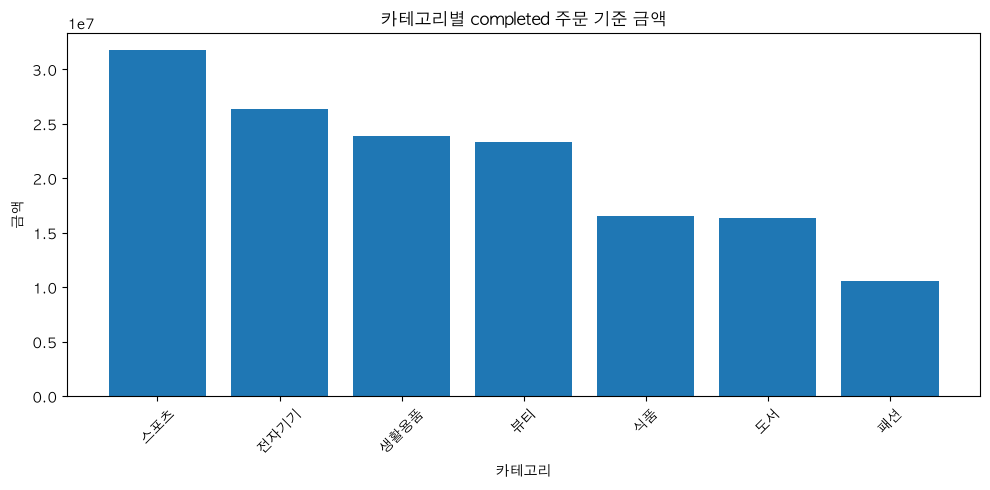

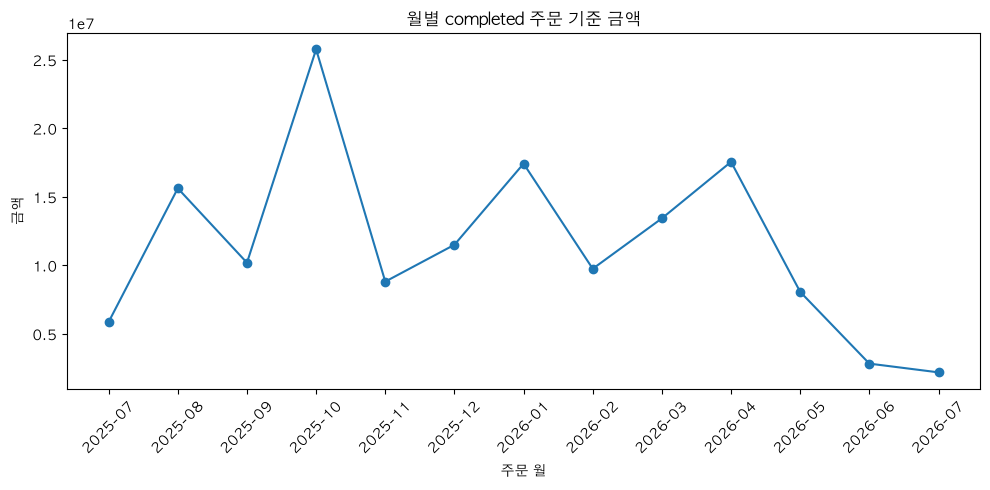

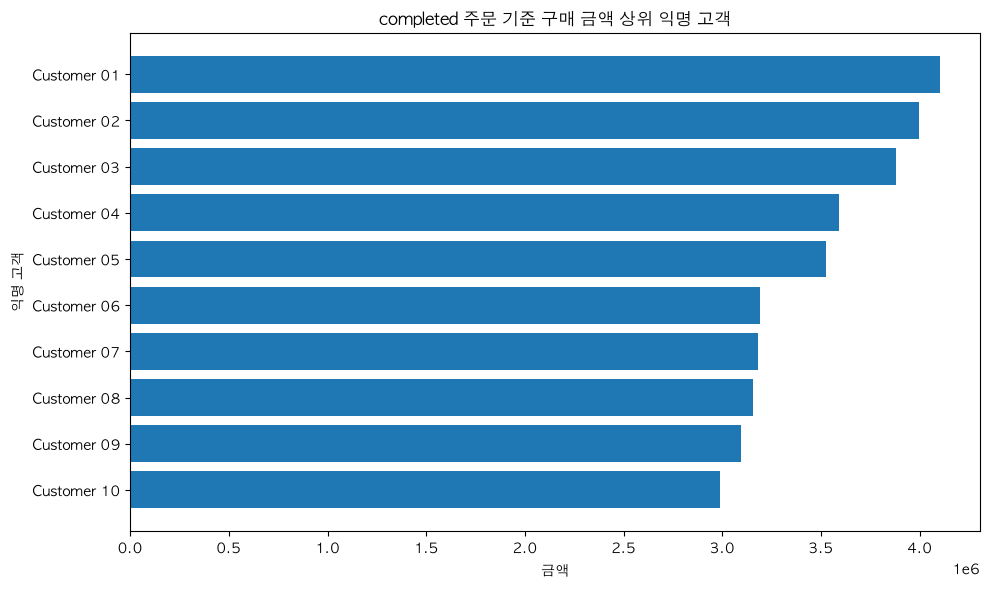

,figure,points,status
0,ch08_category_sales.png,7,PASS
1,ch08_monthly_sales.png,13,PASS
2,ch08_top_customers.png,10,PASS


In [15]:
# 실제 저장·표시되는 공식 그래프의 artist 좌표를 원본 표와 대조
import src.midterm_project as project_module
original_save_figure = project_module._save_figure
figure_checks = []
def checked_save_figure(fig, output_path, show=False):
    ax = fig.axes[0]
    if output_path.name == "ch08_category_sales.png":
        actual = [patch.get_height() for patch in ax.patches]
        expected = category_sales.total_sales.to_numpy()
    elif output_path.name == "ch08_monthly_sales.png":
        actual = ax.lines[0].get_ydata()
        expected = monthly_sales.total_sales.to_numpy()
        assert list(ax.lines[0].get_xdata()) == monthly_sales.order_month.astype(str).tolist()
    else:
        actual = [patch.get_width() for patch in ax.patches]
        expected = customer_sales_public.head(10).sort_values("total_sales").total_sales.to_numpy()
    assert np.asarray(actual).shape == expected.shape
    assert np.allclose(actual, expected, rtol=0, atol=1e-6)
    figure_checks.append({"figure": output_path.name, "points": len(expected), "status": "PASS"})
    original_save_figure(fig, output_path, show)
project_module._save_figure = checked_save_figure
saved_figures = create_project_figures(analysis_tables, FIGURE_DIR, show=True)
display(pd.DataFrame(figure_checks))


### 그래프 관찰과 해석

- 카테고리 막대는 항목별 크기 비교에 적합하며 스포츠 금액이 가장 큼, 수량·단가 분리 분석의 출발점으로 봄
- 고객 가로 막대는 상위 라벨을 읽기 쉬우며 Customer 01 금액이 가장 큼, 구매 빈도와 함께 확인할 가치 있음
- 월별 선은 시간 순서 비교에 적합하며 2025-10 정점 이후 증감이 반복됨, 지속 추세나 계절성으로 판단하기 어려움
- 저장되는 세 그래프의 실제 막대 높이·너비와 선 좌표를 원본 집계값과 대조하여 일치함
- 그래프만으로 광고 효과·수익성·충성도·고객 선호 원인을 말할 수 없음


## 14. Markdown 보고서 생성

보고서에는 계산 기준, PK/FK·병합, `line_total`, total consistency, 개인정보, 최종 Validation을 함께 남깁니다.


In [16]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path.name)
print(report_text[:1800])


보고서 저장: ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"`인 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 검증했습니다.
- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.
- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.
- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150                  6
order_items       764            5             764  

## 15. 전체 파이프라인 재실행

단계별 셀을 확인한 뒤에는 `run_midterm_project()`로 원본부터 보고서까지 다시 실행합니다. Notebook의 이전 메모리 상태에 의존하지 않는지 확인하는 단계입니다.


In [17]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

display(project_result["project_validation"])
print(project_result["report_path"].name)


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


ch08_midterm_report.md


## 16. 최종 산출물 검증

필수 CSV·PNG·Markdown이 존재하고 비어 있지 않은지 확인합니다.


In [18]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


## 17. LLM 검토 프롬프트 예시

원본 고객 행이나 직접 식별정보 대신 비식별 검증 Evidence를 제공합니다.

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

계산 기준:
- line_total = quantity × unit_price
- 금액성 분석은 order_status == completed만 사용

검증 결과:
- PK 결측/중복: 0
- FK 미매칭: 0
- merge checks: PASS
- category/month/customer totals: source total과 일치
- completed 주문 날짜 오류: 0
- 공개 고객 CSV에 원본 customer_id 없음

다음을 검토해 주세요.
1. 아직 확인하지 않은 분석 위험
2. 과도한 해석이 될 수 있는 표현
3. 보고서에 반드시 적어야 할 계산 기준
4. 추가로 필요한 검증
5. 데이터에 없는 원인은 추정하지 않기
```

LLM은 검토 범위를 넓히는 도구이지 프로젝트의 최종 승인자가 아닙니다.


## 18. 실습 과제

1. 핵심 EDA 결과 3개를 선택하고 각각 근거와 한계를 작성합니다.
2. 대표 그래프 2~4개를 선택하고 원본 집계값과 일치하는지 확인합니다.
3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인합니다.
4. 공개 고객 CSV에 개인정보가 없는지 다시 확인합니다.
5. LLM을 사용했다면 목적·Prompt 요약·제안·반영 여부·사람의 검증 근거를 기록합니다.
6. `python scripts/run_midterm_project.py`로 전체 프로젝트를 다시 실행하고 Notebook의 핵심 수치와 비교합니다.


In [19]:
# 같은 환경의 새 프로세스에서 공식 명령 실행
import subprocess
before = {p.name: p.read_bytes() for p in REPORT_DIR.glob("*.csv")}
child_env = os.environ.copy()
child_env["PYTHONPATH"] = str(PROJECT_ROOT)
child_env["MPLBACKEND"] = "Agg"
run = subprocess.run([sys.executable, "scripts/run_midterm_project.py"], cwd=PROJECT_ROOT,
                     env=child_env, capture_output=True, text=True)
assert run.returncode == 0, run.stderr
print("python scripts/run_midterm_project.py: exit", run.returncode)
for filename, content in before.items():
    assert (REPORT_DIR / filename).read_bytes() == content, filename
print("재실행 CSV 15개 바이트 일치 PASS")
display(pd.read_csv(REPORT_DIR / "ch08_project_validation.csv"))
# pandas 집계와 별개로 표준 CSV + Decimal 검산
import csv
from decimal import Decimal
with (PROCESSED_DIR / "orders_clean.csv").open(encoding="utf-8-sig") as f:
    statuses = {r["order_id"]:r["order_status"] for r in csv.DictReader(f)}
with (PROCESSED_DIR / "order_items_clean.csv").open(encoding="utf-8-sig") as f:
    independent = sum((Decimal(r["quantity"])*Decimal(r["unit_price"]) for r in csv.DictReader(f) if statuses[r["order_id"]] == "completed"), Decimal(0))
for table in [category_sales, monthly_sales, customer_sales_public]:
    assert np.isclose(float(independent), table.total_sales.sum(), rtol=0, atol=1e-6)
print("독립 Decimal 검산:", independent, "PASS")


python scripts/run_midterm_project.py: exit 0
재실행 CSV 15개 바이트 일치 PASS


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


독립 Decimal 검산: 148990000 PASS


## 정리

이번 장에서는 원본 데이터 확인, 전처리, PK/FK, 병합, `line_total`, completed 범위, total consistency, 날짜, 개인정보, 시각화, 보고서, 최종 Validation을 하나의 프로젝트로 연결했습니다.

기억할 핵심은 다음과 같습니다.

```text
실행 성공 ≠ 검증 완료
같은 의미의 숫자는 서로 다른 집계에서도 같아야 한다
공개 결과에는 불필요한 개인정보를 남기지 않는다
프로젝트는 원본부터 다시 실행할 수 있어야 한다
```


In [20]:
# Notebook 밖 생성 결과를 선택하여 제출 이미지로 보존
# chapter08 또는 저장소 루트에서 실행해도 같은 제출 위치 사용
cwd = Path.cwd()
submission_dir = cwd if (cwd / "chapter08.ipynb").exists() else cwd / "chapter08"
assert (submission_dir / "chapter08.ipynb").exists(), "Notebook 폴더 또는 과제 저장소 루트에서 실행하세요"
image_dir = submission_dir / "images"
image_dir.mkdir(exist_ok=True)
for filename in ["ch08_category_sales.png", "ch08_top_customers.png"]:
    shutil.copy2(FIGURE_DIR / filename, image_dir / filename)
for filename, table in [("step02_data_validation.png", preprocessing_comparison), ("step06_reproduce.png", pd.read_csv(REPORT_DIR / "ch08_project_validation.csv"))]:
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.axis("off")
    ax.table(cellText=table.astype(str).values, colLabels=table.columns, loc="center", cellLoc="left").auto_set_font_size(False)
    fig.tight_layout()
    fig.savefig(image_dir / filename, dpi=140, bbox_inches="tight")
    plt.close(fig)
print("Evidence 이미지 4개 저장함: 캡처가 아닌 실제 실행표·그래프 이미지")


Evidence 이미지 4개 저장함: 캡처가 아닌 실제 실행표·그래프 이미지


# Chapter 08 답안 양식. 작은 데이터 분석 프로젝트 완성하기

> 이 내용을 `chapter08.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보
이름: 장태원  
GitHub ID: pmsky1  
작성일: 2026-11-02  
최종 Notebook URL: https://github.com/pmsky1/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb  

## 1. 프로젝트 질문
### 분석 질문

- 카테고리별 금액 차이, 월별 금액과 주문 수 변화, 상위 익명 고객의 구매 규모·빈도를 확인함

### 분석 범위

- 공식 원본의 2025-07~2026-07 전체 기간 중 completed 주문 상세를 대상으로 함

### 사용할 데이터와 지표

- customers·products·orders·order_items를 사용하고 금액·수량·비중·고유 주문 수·평균 주문 금액을 비교함

### 계산 기준
- `order_status == "completed"` 적용 여부: 적용함
- `line_total = quantity × unit_price` 확인 여부: 764행 모두 일치함

### 완료 기준

- PK 결측·중복 0건, FK 미매칭 0건, 병합 행 수 유지, 날짜 오류 0건, 네 총합 일치, 개인정보 점검 및 최종 Validation 전체 PASS로 정함

## 2. 입력 데이터와 전처리 검증
- 사용 원본 파일: 공식 커밋 6105f42의 data/raw CSV 4종, 파일별 SHA-256 고정함
- shape: 고객 150×6, 상품 100×4, 주문 300×5, 상세 764×5
- 핵심 결측/중복 결과: 컬럼별 결측은 위 실행표 참조, PK 결측·중복 및 전체 행 중복 0건
- 전처리 전후 변화: 네 파일의 행 수 변화 0건, 주문 월·요일 2컬럼과 상세 line_total 1컬럼 추가함

![입력 데이터 검증](images/step02_data_validation.png)

### 나의 해석과 판단

- 이번 공식 원본은 전처리 후 삭제된 행이 없고 파생 컬럼만 추가되어 행 제외에 따른 금액 감소 없음
- 가격·수량·단가는 양수만 유지하고 문자열 공백·상태 표기를 정리하며 날짜형으로 변환하는 공식 규칙을 적용함

### 한계와 추가 확인 사항

- 행 수 유지와 키 검증 통과만으로 원본의 업무적 정확성까지 보장할 수 없음, 누락 주문과 실제 거래 여부는 원천 시스템 확인 필요함

## 3. PK/FK·병합 검증
### PK 결과

- 네 PK의 결측·중복 모두 0건, 전체 PASS
- 결측: 0건
- 중복: 0건
- PASS/FAIL: PASS

### FK 결과

- 세 관계의 미매칭 모두 0건, 전체 PASS
- 미매칭: 0건
- PASS/FAIL: PASS

### 병합 결과

- many_to_one 2개와 one_to_one 1개 모두 행 수 유지·미매칭 0건이며 상세 표는 실행 결과에서 확인함
- validate 관계: many_to_one 2개, one_to_one 1개
- 병합 전 행 수: 주문 연결 764, 상품 연결 474, 고객 연결 100
- 병합 후 행 수: 각각 764, 474, 100으로 유지함
- 미매칭: 0건
- PASS/FAIL: PASS

### 나의 해석과 판단

- 주문·상품·고객 연결에서 미매칭과 행 증식이 없어 병합으로 인한 금액 중복 가능성을 점검함
- 연결 성공은 고객·상품 속성값 자체가 정확하다는 뜻은 아니므로 업무적 검증은 별도로 필요함

## 4. 핵심 EDA 결과
### 결과 1
- 수치/표: 스포츠 31,743,000원, 21.31%, 295개
- 결과 관찰: 스포츠 금액 비중이 가장 큼
- 나의 해석과 판단: 현재 completed 금액 기여가 가장 큼
- 업무·분석적 의미: 수량과 단가를 나눠 비교할 가치 있음
- 한계: 비용이 없어 수익성·선호 원인은 알 수 없음

### 결과 2
- 수치/표: 2025-10 25,766,000원·26주문, 2026-07 2,188,000원·2주문
- 결과 관찰: 월별 증감이 반복되며 2025-10 금액이 가장 큼
- 나의 해석과 판단: 지속 증가 추세라고 보기 어려움
- 업무·분석적 의미: 주문 수와 평균 주문 금액을 분리해서 확인할 가치 있음
- 한계: 월별 수집 완전성과 기간 말 부분월 여부 확인 필요함

### 결과 3
- 수치/표: Customer 01 4,100,000원·5주문·평균 820,000원
- 결과 관찰: 상위 금액 고객도 주문 수와 평균 금액이 다름
- 나의 해석과 판단: 누적 금액만으로 반복 구매 성향을 단정하기 어려움
- 업무·분석적 의미: 구매 빈도와 최근 구매일을 함께 볼 가치 있음
- 한계: 기간 밖 구매와 이익·충성도는 알 수 없음

## 5. Total consistency와 날짜 검증
- completed source total: 148,990,000원
- category total: 148,990,000원
- monthly total: 148,990,000원
- customer total: 148,990,000원
- 총합 일치 여부: 네 합계 일치함, Decimal 독립 검산도 일치함
- completed 주문 날짜 오류 건수: 0건
- 날짜 오류 영향 금액: 0원

### 불일치가 있었다면 원인

- 이번 원본에서는 불일치 없음, 이전 Chapter의 다른 데이터 총액과 혼합하지 않음

## 6. 대표 시각화
![대표 그래프 1](images/ch08_category_sales.png)

- 카테고리별 크기 비교에 적합한 막대를 선택함, 실제 높이와 원본 금액 일치함
- 스포츠 31,743,000원으로 가장 크며 현재 완료 금액 기여가 크다고 판단함, 비용이 없어 수익성은 판단할 수 없음

![대표 그래프 2](images/ch08_top_customers.png)

- 고객 라벨을 읽기 쉬운 가로 막대를 선택함, 실제 너비와 원본 금액 일치함
- 상위 10명은 299만원~410만원이며 금액과 빈도를 함께 볼 가치가 있음, 충성도·기간 밖 구매는 판단할 수 없음


### 그래프 선택 이유

- 카테고리 비교는 막대, 상위 익명 고객 비교는 가로 막대로 선택함

### 그래프와 원본 집계값 일치 여부

- 실제 저장되는 카테고리·고객 막대와 월별 선의 좌표를 원본 배열과 rtol=0, atol=1e-6으로 대조하여 일치함

### 그래프에서 직접 관찰한 사실

- 스포츠 금액이 가장 크고 Customer 01~10의 금액은 299만원~410만원임
- 나의 해석: 현재 완료 주문 금액의 분포이며 전체 고객 선호를 설명하지는 못함

### 그래프만으로 말할 수 없는 것

- 광고 효과·고객 선호 원인·수익성·고객 충성도는 판단할 수 없음

## 7. 개인정보 검증
- 공개 고객 CSV 컬럼: customer_label, city, order_count, total_sales, avg_order_value
- 원본 `customer_id` 포함 여부: 없음
- 이름/이메일/전화번호/주소 포함 여부: 없음
- 익명 라벨 방식: 금액 순위 기반 Customer 01 등 사용함
- PASS/FAIL: PASS

### 나의 판단

- 원본 ID를 공개하지 않고 순위 라벨로 교체함, city와 구매 요약만으로도 재식별 위험이 완전히 없어지는 것은 아님

## 8. 최종 Validation
`reports/ch08_project_validation.csv`의 결과를 요약합니다.

| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | --- | --- |
| pk_integrity | PASS | 위 실행표 및 재실행 CSV와 대조함 |
| fk_integrity | PASS | 위 실행표 및 재실행 CSV와 대조함 |
| merge_checks_pass | PASS | 위 실행표 및 재실행 CSV와 대조함 |
| line_total_consistency | PASS | 위 실행표 및 재실행 CSV와 대조함 |
| completed_total_consistency | PASS | 위 실행표 및 재실행 CSV와 대조함 |
| category_sales_ratio_pct_sum | PASS | 위 실행표 및 재실행 CSV와 대조함 |
| completed_rows_with_invalid_order_date | PASS | 위 실행표 및 재실행 CSV와 대조함 |
| public_customer_columns_safe | PASS | 위 실행표 및 재실행 CSV와 대조함 |

### FAIL이 있었다면 수정 내용

- 데이터 검증 FAIL 없음, 숫자를 맞추기 위한 행 삭제나 날짜 임의 대체 없음

## 9. LLM 활용 기록
- 사용 여부: ChatGPT 사용함
- 사용 목적: 코드 작성·검증 설계·해석 초안 보조
- Safe Context: 공개 스키마와 비식별 집계·검증 건수 사용, 원본 고객 행은 대화에 제공하지 않음
- Prompt 요약: 제공한 Chapter 08 요구사항에 따라 질문부터 재실행까지 검증 가능한 Notebook 작성
- 제안 요약: 공식 로직 포함, 원본 해시 고정, Decimal 검산 및 실제 그래프 좌표 대조
- 반영/수정/보류: 코드와 검증 반영, 수익성·광고 효과 등 데이터 밖 원인 추정 제외
- 사람이 검증한 근거: 자동 실행·검산 근거는 위 출력에 남김, 원본 CSV 독립 검산, 집계표·그래프 좌표 대조, 전체 재실행 결과를 검증 근거로 확인함

## 10. 프로젝트 재현 확인
- `python scripts/run_midterm_project.py` 실행 여부: 같은 Python 환경의 별도 프로세스로 실행함
- 재실행 결과: 종료 코드 0, 8개 Validation 전체 PASS
- Notebook과 핵심 수치 일치 여부: 생성 CSV 15개 바이트 일치 및 source total 독립 검산 일치
- 생성된 핵심 Evidence 파일 확인 여부: CSV 15개·PNG 3개·보고서 존재 및 비어 있지 않음 확인

![재실행 결과](images/step06_reproduce.png)

### 나의 해석과 판단

- 같은 원본과 코드로 결과를 다시 얻어 이전 메모리나 실행 순서에 따른 오류를 줄일 수 있음

재실행 가능한 프로젝트가 왜 중요한지 작성하세요.

## 11. 최종 프로젝트 요약
### 핵심 인사이트 3개
1. 스포츠 금액 비중 21.31%로 기여가 가장 큼 → 수량·단가 분리 확인 필요하며 수익성은 알 수 없음
2. 2025-10 금액·주문 수가 가장 큼 → 주문 규모 차이를 추가 확인할 가치가 있으며 계절성 단정 불가
3. Customer 01은 410만원·5주문 → 금액과 빈도를 함께 확인할 가치가 있으며 충성도 단정 불가

### 가장 중요한 업무·분석적 의미

- 같은 범위의 총합을 먼저 맞춰야 카테고리·월·고객 결과를 함께 비교할 수 있음

### 현재 분석의 한계

- 실습용 표본이며 비용·마진·광고·실제 영업 기간 정보가 없어 수익성과 변화 원인을 판단할 수 없음

### 다음 분석 제안
1. 카테고리별 수량과 평균 단가 분리
2. 월별 데이터 수집 완전성과 평균 주문 금액 비교
3. 고객별 최근 구매일과 반복 구매 간격 비교

## 최종 체크
- [x] 질문과 지표가 연결됩니다.
- [x] 원본 데이터에서 다시 시작했습니다.
- [x] PK/FK·병합 검증 근거가 있습니다.
- [x] `line_total` 계산 관계를 확인했습니다.
- [x] 금액성 분석은 completed 범위를 사용했습니다.
- [x] category/month/customer 총합이 source total과 일치합니다.
- [x] 날짜 오류를 확인했습니다.
- [x] 공개 고객 결과에서 원본 ID와 직접 식별정보를 제거했습니다.
- [x] 대표 그래프와 원본 집계값을 비교했습니다.
- [x] 원인 과대 해석이 없습니다.
- [x] 최종 Validation이 모두 PASS입니다.
- [x] 전체 프로젝트를 재실행했습니다.
- [x] 한계와 다음 분석을 작성했습니다.
- [ ] 최종 Notebook URL을 제출합니다.
